# Laborator „Modele Generative”: sistem RAG pe Codul muncii al Republicii Moldova

**Obiectiv:** construirea unui sistem *Retrieval-Augmented Generation* (RAG) pe un document propriu, **Codul muncii al RM (Legea nr. 154/2003)**, și compararea a trei arhitecturi de retrieval:

| Metoda | Retrieval | Ce demonstrează |
|---|---|---|
| **Naive RAG** | doar căutare densă (embeddings + Qdrant) | baseline-ul „clasic” |
| **Hybrid RAG** | BM25 + căutare densă, fuzionate cu **RRF** | combinarea căutării lexicale cu cea semantică |
| **Advanced RAG** | Hybrid RAG + **re-ranking cu cross-encoder** | rafinarea relevanței cu un model mai precis |

Tot procesul e scris explicit în Python, **fără LangChain / LlamaIndex**, ca fiecare pas (curățare, chunking, embeddings, RRF, re-ranking, prompt) să fie vizibil și verificabil.

---

### Pregătirea mediului (o singură dată, în terminal)

```bash
uv init rag-codul-muncii --python 3.12
cd rag-codul-muncii
rm -f main.py hello.py
mkdir -p data/raw data/processed cache notebooks

uv add requests beautifulsoup4 lxml unidecode \
       numpy pandas matplotlib tqdm python-dotenv \
       sentence-transformers qdrant-client rank-bm25 \
       openai gradio
uv add --dev jupyterlab ipykernel ipywidgets

uv run python -m ipykernel install --user --name rag-codul-muncii --display-name "RAG Codul Muncii (uv)"
uv run jupyter lab
```

*(Opțional, pe server fără GPU)* adaugă în `pyproject.toml`, **înainte** de `uv add`, indexul PyTorch pentru CPU, ca să nu se descarce varianta CUDA (câțiva GB):

```toml
[[tool.uv.index]]
name = "pytorch-cpu"
url = "https://download.pytorch.org/whl/cpu"
explicit = true

[tool.uv.sources]
torch = { index = "pytorch-cpu" }
```

Fișierul `.env` din rădăcina proiectului (nu se predă, se predă doar `.env.example`):

```bash
LLM_PROVIDER=ollama            # ollama | openrouter
OLLAMA_API_KEY=...
OPENROUTER_API_KEY=...
# LLM_MODEL=gpt-oss:120b       # opțional, suprascrie modelul implicit
```

Notebook-ul se pune în `notebooks/` și se rulează cu kernelul **„RAG Codul Muncii (uv)”**.

---

### Cuprins
1. Introducere și arhitectură
2. Configurare
3. Achiziția datelor
4. Curățarea textului
5. Parsarea structurii juridice
6. Chunking
7. Embeddings (dense)
8. Indexul vectorial: Qdrant în memorie
9. Indexul lexical: BM25
10. Cele trei metode de retrieval
11. Generarea răspunsului cu LLM
12. Evaluare
13. Chat interactiv cu Gradio
14. Concluzii

## 1. Introducere și arhitectură

### 1.1 Ce este RAG
Un LLM „știe” doar ce a văzut la antrenare și poate **halucina** detalii (de exemplu, numere de articole sau termene). RAG rezolvă problema în doi pași:

1. **Retrieval:** găsim în colecția noastră de documente fragmentele relevante pentru întrebare;
2. **Generation:** dăm aceste fragmente LLM-ului ca *context* și îi cerem să răspundă **doar** pe baza lor, cu citarea surselor.

### 1.2 Arhitectura sistemului

```
                    ┌──────────────────────── INGESTIE (offline) ────────────────────────┐
 legis.md / fișier ─► descărcare ─► curățare ─► parsare articole ─► chunking structural
                                                                       │
                                     ┌─────────────────────────────────┴───────────────┐
                                     ▼                                                 ▼
                          embeddings (multilingual-e5)                          tokenizare RO
                                     ▼                                                 ▼
                          Qdrant :memory: (cosinus)                              index BM25
                    └──────────────────────────────────────────────────────────────────────┘

                    ┌──────────────────────── INTEROGARE (online) ───────────────────────┐
 întrebare ─► (reformulare din istoric) ─► Naive  : dense top-k
                                           Hybrid : dense top-20 + BM25 top-20 ─► RRF ─► top-k
                                           Advanced: RRF top-15 ─► cross-encoder ─► top-k
                                                       │
                                                       ▼
                              prompt (context + reguli + întrebare) ─► LLM ─► răspuns + citări
                    └──────────────────────────────────────────────────────────────────────┘
```

### 1.3 De ce Codul muncii
- are **sute de articole**, suficient ca diferențele dintre metode să fie vizibile;
- are o **structură clară** (titluri → capitole → articole → alineate), ceea ce permite chunking pe articole;
- fiecare fragment are un **identificator verificabil** (numărul articolului), deci putem evalua obiectiv retrieval-ul;
- conține atât **termeni exacți** („preaviz”, „perioada de probă”), unde BM25 e bun, cât și situații descrise **în limbaj colocvial** („mă poate da afară?”), unde căutarea semantică e mai bună.

> ⚠️ **Disclaimer:** proiect strict educațional. Răspunsurile sistemului **nu constituie consultanță juridică**. Textul legii folosit e o versiune fixă, de la data descărcării, și poate să nu includă modificările ulterioare.

## 2. Configurare

### 2.1 Importuri și versiunile bibliotecilor

Afișăm versiunile ca rezultatele să poată fi reproduse: aceeași versiune de model și bibliotecă dă aceleași embeddings.

In [1]:
import os
import re
import json
import time
import random
import hashlib
import unicodedata
import datetime as dt
from pathlib import Path
from dataclasses import dataclass, field
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from unidecode import unidecode
from tqdm.auto import tqdm
from dotenv import load_dotenv
from IPython.display import display, Markdown

import torch
from sentence_transformers import SentenceTransformer, CrossEncoder
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, VectorParams, PointStruct
from rank_bm25 import BM25Okapi
from openai import OpenAI
import gradio as gr

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

for pkg in ["numpy", "pandas", "torch", "sentence-transformers", "qdrant-client",
            "rank-bm25", "openai", "gradio", "beautifulsoup4"]:
    try:
        print(f"{pkg:<22} {version(pkg)}")
    except Exception:
        print(f"{pkg:<22} (necunoscută)")

numpy                  2.5.4
pandas                 3.1.0
torch                  2.14.1
sentence-transformers  6.2.0
qdrant-client          1.20.0
rank-bm25              0.2.2
openai                 3.37.0
gradio                 6.30.0
beautifulsoup4         4.15.0


### 2.2 Constante și parametri

Toți parametrii experimentului sunt într-un singur loc. Fiecare are un comentariu care explică ce controlează.

| Parametru | Valoare | Rol |
|---|---|---|
| `EMBED_MODEL_NAME` | `intfloat/multilingual-e5-base` | bi-encoder multilingv (768 dim.), funcționează bine pe română |
| `RERANK_MODEL_NAME` | `BAAI/bge-reranker-v2-m3` | cross-encoder multilingv pentru re-ranking |
| `MAX_CHUNK_CHARS` | 1200 | limita unui chunk; ~350–450 de tokeni, sub limita de 512 a modelului e5 |
| `CANDIDATES` | 20 | câți candidați aduce fiecare retriever (dense / BM25) înainte de RRF |
| `RERANK_CANDIDATES` | 15 | câți candidați RRF trec prin cross-encoder (cost CPU!) |
| `K_RRF` | 60 | constanta de netezire din formula RRF |

In [15]:
# --- Căi (notebook-ul stă în notebooks/, deci rădăcina proiectului e directorul părinte)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
CACHE_DIR = PROJECT_ROOT / "cache"
for d in (DATA_RAW, DATA_PROCESSED, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

RAW_HTML = DATA_RAW / "codul_muncii.html"   # pagina salvată (descărcată automat sau manual)
RAW_TXT = DATA_RAW / "codul_muncii.txt"     # alternativă: textul copiat din browser
META_FILE = DATA_RAW / "meta.json"
CLEAN_TXT = DATA_PROCESSED / "codul_muncii_clean.txt"
ARTICLES_CSV = DATA_PROCESSED / "articole.csv"
CHUNKS_JSONL = DATA_PROCESSED / "chunks.jsonl"

SOURCE_URL = os.getenv("CODUL_MUNCII_URL",
                       "https://www.legis.md/cautare/getResults?doc_id=8238&lang=ro")

# --- Modele locale
EMBED_MODEL_NAME = "intfloat/multilingual-e5-base"
RERANK_MODEL_NAME = "BAAI/bge-reranker-v2-m3"
QUERY_PREFIX = "query: "      # prefixe cerute de familia e5 (fără ele calitatea scade)
PASSAGE_PREFIX = "passage: "

# --- Chunking
MAX_CHUNK_CHARS = 1200        # chunking structural: limita pentru un fragment de articol
FIXED_CHUNK_SIZE = 1000       # chunking fix (baseline)
FIXED_CHUNK_OVERLAP = 150

# --- Retrieval
TOP_K = 5                     # câte fragmente ajung în promptul LLM
CANDIDATES = 20               # candidați per retriever înainte de fuziune
RERANK_CANDIDATES = 15        # candidați trimiși la cross-encoder
K_RRF = 60                    # constanta din RRF
EVAL_DEPTH = 10               # adâncimea listelor la evaluare (MRR@10)

# --- LLM (API compatibil OpenAI)
LLM_PROVIDER = os.getenv("LLM_PROVIDER", "ollama").lower()
PROVIDERS = {
    "ollama": {
        "base_url": "https://ollama.com/v1",
        "api_key_env": "OLLAMA_API_KEY",
        "model": os.getenv("LLM_MODEL", "gpt-oss:120b"),
    },
    "openrouter": {
        "base_url": "https://openrouter.ai/api/v1",
        "api_key_env": "OPENROUTER_API_KEY",
        "model": os.getenv("LLM_MODEL", "openai/gpt-oss-120b"),
    },
}
LLM_TEMPERATURE = 0.1         # temperatură mică: răspunsuri factuale, puțin „creative”
LLM_CALL_DELAY = 0.5          # pauză între apeluri la evaluare (evită rate-limit)

# --- Ce rulăm
RUN_GENERATION_EVAL = True    # evaluarea răspunsurilor LLM (~54 de apeluri API)
RUN_ABLATIONS = True          # experimente suplimentare (mai multe embeddings de calculat)

SEED = 42
COLLECTION_MAIN = "codul_muncii_structural"

print("Rădăcina proiectului:", PROJECT_ROOT)

Rădăcina proiectului: /home/ivan/tmp/new/llm/laborator_2


### 2.3 Cheile API

Cheile se citesc din `.env`, nu se scriu niciodată în notebook. Dacă cheia lipsește, capitolele 1–10 rulează normal (sunt locale), iar capitolele de generare afișează un mesaj explicativ.

In [16]:
if LLM_PROVIDER not in PROVIDERS:
    raise ValueError(f"LLM_PROVIDER necunoscut: {LLM_PROVIDER}. Opțiuni: {list(PROVIDERS)}")

LLM_CFG = PROVIDERS[LLM_PROVIDER]
LLM_API_KEY = os.getenv(LLM_CFG["api_key_env"])
LLM_MODEL = LLM_CFG["model"]

print(f"Furnizor LLM : {LLM_PROVIDER}  ({LLM_CFG['base_url']})")
print(f"Model        : {LLM_MODEL}")
if LLM_API_KEY:
    print(f"Cheie API    : găsită ({LLM_CFG['api_key_env']}=...{LLM_API_KEY[-4:]})")
else:
    print(f"ATENȚIE: lipsește {LLM_CFG['api_key_env']} în .env. Generarea (cap. 11–13) nu va funcționa.")

Furnizor LLM : ollama  (https://ollama.com/v1)
Model        : gpt-oss:120b
Cheie API    : găsită (OLLAMA_API_KEY=...miXj)


### 2.4 Reproductibilitate și dispozitiv de calcul

Fixăm seed-urile și detectăm automat dacă avem GPU (CUDA), Apple Silicon (MPS) sau doar CPU.

In [17]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("Dispozitiv:", DEVICE)

Dispozitiv: cpu


## 3. Achiziția datelor

### 3.1 Sursa
Textul oficial consolidat se află în Registrul de stat al actelor juridice: [legis.md – CP154/2003](https://www.legis.md/cautare/getResults?doc_id=8238&lang=ro).

**Problemă practică:** legis.md e protejat de Cloudflare și își încarcă textul prin JavaScript. Un simplu `requests.get()` primește de obicei fie o pagină de verificare („Just a moment…”, HTTP 403), fie doar „Conținutul se încarcă…”. De aceea celula de mai jos procedează astfel:

1. dacă documentul există deja local (`data/raw/codul_muncii.txt` sau `.html`), îl folosește;
2. altfel **încearcă** descărcarea automată și **verifică** dacă a primit textul real (≥ 300 de titluri „Articolul”);
3. dacă descărcarea eșuează, afișează instrucțiuni pentru salvarea manuală (o singură dată).

**Salvarea manuală (oricare variantă):**
- **Varianta A, HTML (recomandată, păstrează indicii de tip 54¹):** deschide pagina în browser, așteaptă să se încarce tot textul, apoi `Ctrl+S` → *„Pagină web, completă”* → salvează ca `data/raw/codul_muncii.html`;
- **Varianta B, text:** în pagina încărcată, `Ctrl+A`, `Ctrl+C`, apoi lipește într-un fișier `data/raw/codul_muncii.txt` (UTF-8).

In [18]:
BROWSER_HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"),
    "Accept-Language": "ro-RO,ro;q=0.9,en;q=0.8",
}
MIN_ARTICLES = 300   # Codul muncii are câteva sute de articole; sub acest prag textul e incomplet

ARTICLE_COUNT_RE = re.compile(r"Articolul(?:\s|&nbsp;|<[^>]+>)+\d+")


def count_article_headings(text: str) -> int:
    """Numără aparițiile de tipul 'Articolul N' (și în HTML brut)."""
    return len(ARTICLE_COUNT_RE.findall(text))


def looks_like_cloudflare(html: str) -> bool:
    markers = ("Just a moment", "cf_chl", "challenge-platform", "Enable JavaScript and cookies")
    return any(m in html for m in markers)


def try_download(url: str, dest: Path) -> bool:
    print(f"Încerc descărcarea automată: {url}")
    try:
        resp = requests.get(url, headers=BROWSER_HEADERS, timeout=60)
    except requests.RequestException as exc:
        print(f"  Eroare de rețea: {exc}")
        return False
    html = resp.text
    print(f"  HTTP {resp.status_code}, {len(html):,} caractere")
    if resp.status_code != 200:
        print("  Serverul a refuzat cererea.")
        return False
    if looks_like_cloudflare(html):
        print("  Am primit pagina de verificare Cloudflare, nu documentul.")
        return False
    n = count_article_headings(html)
    if n < MIN_ARTICLES:
        print(f"  Doar {n} titluri 'Articolul': conținutul se încarcă probabil prin JavaScript.")
        return False
    dest.write_text(html, encoding="utf-8")
    print(f"  Salvat în {dest}")
    return True


MANUAL_INSTRUCTIONS = f"""
Nu am putut obține automat textul Codului muncii.
Salvează-l manual O SINGURĂ DATĂ, apoi rulează din nou celula:

  1. Deschide în browser: {SOURCE_URL}
  2. Așteaptă să se încarce tot textul (derulează până la final).
  3a. Ctrl+S → „Pagină web, completă” → {RAW_HTML}
      SAU
  3b. Ctrl+A, Ctrl+C → lipește într-un fișier text UTF-8: {RAW_TXT}
"""


def acquire_source():
    if RAW_TXT.exists():
        print(f"Folosesc fișierul text existent: {RAW_TXT}")
        return "txt", RAW_TXT
    if RAW_HTML.exists():
        print(f"Folosesc fișierul HTML existent: {RAW_HTML}")
        return "html", RAW_HTML
    if try_download(SOURCE_URL, RAW_HTML):
        return "html", RAW_HTML
    raise FileNotFoundError(MANUAL_INSTRUCTIONS)


SOURCE_KIND, SOURCE_PATH = acquire_source()

Folosesc fișierul HTML existent: /home/ivan/tmp/new/llm/laborator_2/data/raw/codul_muncii.html


### 3.2 Verificarea conținutului
Un fișier poate exista, dar să fie gol sau trunchiat (de exemplu, un HTML salvat înainte să se încarce textul). Verificăm numărul de articole **înainte** de a continua.

In [19]:
raw_content = SOURCE_PATH.read_text(encoding="utf-8", errors="replace")
n_heads = count_article_headings(raw_content)
print(f"Tip sursă: {SOURCE_KIND} | dimensiune: {len(raw_content):,} caractere | titluri 'Articolul': {n_heads}")

if n_heads < MIN_ARTICLES:
    raise ValueError(f"Fișierul {SOURCE_PATH.name} pare incomplet ({n_heads} articole).\n{MANUAL_INSTRUCTIONS}")

Tip sursă: html | dimensiune: 1,188,068 caractere | titluri 'Articolul': 421


### 3.3 Metadatele sursei
Legea se modifică des, deci notăm **data obținerii** și **hash-ul SHA-256** al fișierului. Astfel știm exact pe ce versiune s-au calculat rezultatele.

In [20]:
sha256 = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
old_meta = json.loads(META_FILE.read_text(encoding="utf-8")) if META_FILE.exists() else {}

if old_meta.get("sha256") == sha256:
    meta = old_meta
else:
    meta = {
        "source_url": SOURCE_URL,
        "source_kind": SOURCE_KIND,
        "file": SOURCE_PATH.name,
        "sha256": sha256,
        "size_bytes": SOURCE_PATH.stat().st_size,
        "retrieved_at": dt.datetime.fromtimestamp(SOURCE_PATH.stat().st_mtime).isoformat(timespec="seconds"),
    }
    META_FILE.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "source_url": "https://www.legis.md/cautare/getResults?doc_id=8238&lang=ro",
  "source_kind": "html",
  "file": "codul_muncii.html",
  "sha256": "433744ddee26bd2760e9c92684118ba77c053f58c75d7e6be065968382aba264",
  "size_bytes": 1210788,
  "retrieved_at": "2026-10-26T18:18:28"
}


## 4. Curățarea textului

Calitatea retrieval-ului depinde direct de calitatea textului. Zgomotul (meniuri de site, note de modificare, caractere Unicode inconsistente) strică atât embeddings-urile, cât și BM25.

### 4.1 Din HTML în text simplu
- eliminăm elementele care nu fac parte din lege (`script`, `style`, `nav`, `header`, `footer`...);
- transformăm `<sup>1</sup>` în `^1`, ca `Articolul 54<sup>1</sup>` să devină `Articolul 54^1` (altfel ar ieși „541”);
- punem salt de linie doar **după elementele de tip bloc** (`p`, `div`, `li`...), nu între orice etichete, ca titlul unui articol să rămână pe aceeași linie cu numărul lui.

In [21]:
BLOCK_TAGS = ["p", "div", "li", "tr", "table", "section", "article", "blockquote",
              "h1", "h2", "h3", "h4", "h5", "h6"]
NOISE_TAGS = ["script", "style", "noscript", "nav", "header", "footer", "form",
              "button", "select", "iframe", "svg"]


def html_to_text(html: str) -> str:
    soup = BeautifulSoup(html, "lxml")
    for tag in soup(NOISE_TAGS):
        tag.decompose()
    for sup in soup.find_all("sup"):
        sup.replace_with(f"^{sup.get_text(strip=True)}")
    for br in soup.find_all("br"):
        br.replace_with("\n")
    for tag in soup.find_all(BLOCK_TAGS):
        tag.insert_before("\n")
        tag.insert_after("\n")
    return soup.get_text()


text_raw = html_to_text(raw_content) if SOURCE_KIND == "html" else raw_content
print(f"Text extras: {len(text_raw):,} caractere")

Text extras: 462,131 caractere


### 4.2 Normalizarea Unicode
Textele juridice din RM amestecă **ş/ţ cu sedilă** (U+015F, U+0163) cu **ș/ț cu virgulă** (U+0219, U+021B). Pentru calculator acestea sunt caractere diferite: „şi” ≠ „și”. Unificăm și ghilimelele, cratimele și spațiile speciale (`\xa0`).

In [22]:
CHAR_MAP = {
    "\u015f": "ș", "\u015e": "Ș", "\u0163": "ț", "\u0162": "Ț",      # sedilă → virgulă
    "\u00a0": " ", "\u2009": " ", "\u202f": " ", "\u200b": "", "\ufeff": "",
    "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u00ab": '"', "\u00bb": '"',
    "\u2019": "'", "\u2018": "'",
    "\u2013": "-", "\u2014": "-", "\u2011": "-",
}
CHAR_TABLE = str.maketrans(CHAR_MAP)

KEYWORDS = ["Titlul", "Capitolul", "Secțiunea", "Articolul"]
SPACED_KEYWORD_RE = re.compile(
    r"^(" + "|".join(r"\s?".join(w) for w in KEYWORDS) + r")\b",
    re.I | re.M,
)  # prinde „T i t l u l”, „C a p i t o l u l” etc. la început de rând


def normalize_ro(text: str) -> str:
    text = unicodedata.normalize("NFC", text).translate(CHAR_TABLE)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)                   # spații multiple
    text = "\n".join(line.strip() for line in text.split("\n"))
    text = SPACED_KEYWORD_RE.sub(lambda m: re.sub(r"\s", "", m.group(0)), text)  # „T i t l u l I” → „Titlul I”
    text = re.sub(r"\n{3,}", "\n\n", text)                # linii goale multiple
    return text.strip()

n_cedilla = sum(text_raw.count(c) for c in "\u015f\u015e\u0163\u0162")
text_norm = normalize_ro(text_raw)
print(f"Caractere cu sedilă înlocuite: {n_cedilla:,}")
print(f"Lungime după normalizare: {len(text_norm):,} caractere")

Caractere cu sedilă înlocuite: 5,095
Lungime după normalizare: 447,698 caractere


In [23]:
# În textul normalizat: câte titluri/capitole se văd acum
print(re.findall(r"(?m)^Titlul\s+[IVXLCDM]+(?:\^\d+)?\b", text_norm))
print(len(re.findall(r"(?m)^Capitolul\s+[IVXLCDM]+", text_norm)), "capitole")

['Titlul I', 'Titlul II', 'Titlul III', 'Titlul IV', 'Titlul V', 'Titlul VI', 'Titlul VII', 'Titlul VIII', 'Titlul IX', 'Titlul X', 'Titlul XI', 'Titlul XII', 'Titlul XIII', 'Titlul XIV']
66 capitole


### 4.3 Păstrăm doar corpul legii
Pagina conține și text de site (antet, meniu, subsol). Corpul legii începe la **„Titlul I”** (sau, ca rezervă, la „Articolul 1.”) și se termină înainte de semnătura **„PREȘEDINTELE PARLAMENTULUI”**.

In [24]:
def trim_to_code_body(text: str) -> str:
    m_start = (re.search(r"^Titlul\s+I\b", text, re.M | re.I)
               or re.search(r"^Articolul\s+1\s*\.", text, re.M))
    start = m_start.start() if m_start else 0
    ends = list(re.finditer(r"PREȘEDINTELE\s+PARLAMENTULUI", text[start:], re.I))
    end = start + ends[-1].start() if ends else len(text)
    return text[start:end].strip()


text_body = trim_to_code_body(text_norm)
print(f"Corpul legii: {len(text_body):,} caractere (eliminate {len(text_norm) - len(text_body):,})")
print("\n--- Începutul textului ---\n", text_body[:600])
print("\n--- Sfârșitul textului ---\n", text_body[-400:])

Corpul legii: 437,959 caractere (eliminate 9,739)

--- Începutul textului ---
 Titlul I

DISPOZIȚII GENERALE

Capitolul I

DISPOZIȚII INTRODUCTIVE

Articolul 1. Noțiuni principale

În sensul prezentului cod, se definesc următoarele noțiuni:

agent de muncă temporară - persoana fizică care desfășoară o activitate de întreprinzător sau întreprinderea, instituția ori organizația cu statut de persoană juridică, indiferent de tipul de proprietate, de forma juridică de organizare și de subordonarea departamentală sau apartenența ramurală, care a notificat Inspectoratul de Stat al Muncii privind inițierea activității sale și care încheie cu salariați temporari contracte individ

--- Sfârșitul textului ---
  ce contravin prezentului cod;

f) va întreprinde alte măsuri de punere în aplicare a prezentului cod, de studiere și aplicare a prevederilor acestuia de către subiecții de drept.

(3) Reglementarea și soluționarea situațiilor juridice legate de aplicarea legislației muncii, nereglementate 

### 4.4 Eliminarea notelor de modificare
Versiunea consolidată conține note editoriale de tipul `[Art.86 modificat prin LP... din ..., MO.../...; în vigoare ...]`. Ele **nu sunt conținut normativ**, dar:
- adaugă la BM25 tokeni-zgomot (`lp`, `mo`, numere de Monitor Oficial);
- „diluează” embedding-ul fragmentului.

Le eliminăm cu o expresie regulată care caută paranteze pătrate ce conțin cuvinte specifice notelor.

In [25]:
AMENDMENT_RE = re.compile(
    r"\[[^\[\]]*?(?:modificat|completat|abrogat|introdus|exclus|redactat|suspendat|"
    r"declarat|în vigoare|LP\s?\d|MO\s?\d|Hot\.|HCC)[^\[\]]*?\]",
    re.I | re.S,
)

notes_found = AMENDMENT_RE.findall(text_body)
print(f"Note de modificare găsite: {len(notes_found)}")
for n in notes_found[:3]:
    print("  •", n[:150])

# Exemplu înainte/după, în jurul primei note
m = AMENDMENT_RE.search(text_body)
if m:
    window = text_body[max(0, m.start() - 250): m.end() + 100]
    print("\n--- ÎNAINTE ---\n", window)
    print("\n--- DUPĂ ---\n", AMENDMENT_RE.sub("", window))

text_clean = AMENDMENT_RE.sub("", text_body)
text_clean = re.sub(r"[ \t]+\n", "\n", text_clean)
text_clean = re.sub(r"\n{3,}", "\n\n", text_clean).strip()
print(f"\nCaractere eliminate prin curățarea notelor: {len(text_body) - len(text_clean):,}")

Note de modificare găsite: 2
  • [Art.46 al.(4^1) introdus prin LP154 din 30.07.26, MO375-378/13.08.26 art.393; în vigoare 01.01.27]
  • [Art.90 al.(2), lit. a) textul "într-o mărime care nu va depăși 12 salarii medii lunare ale salariatului" se declară neconstituțional conform HCC9 din

--- ÎNAINTE ---
 i (4) din Legea nr. 133/2016 privind declararea averii și a intereselor personale până la emiterea unui aviz de conformitate favorabil din partea Autorității Naționale de Integritate privind compatibilitatea cu regimul restricțiilor și limitărilor.

[Art.46 al.(4^1) introdus prin LP154 din 30.07.26, MO375-378/13.08.26 art.393; în vigoare 01.01.27]

(5) În calitate de angajator, parte a contractului individual de muncă poate fi orice persoană fiz

--- DUPĂ ---
 i (4) din Legea nr. 133/2016 privind declararea averii și a intereselor personale până la emiterea unui aviz de conformitate favorabil din partea Autorității Naționale de Integritate privind compatibilitatea cu regimul restricții

### 4.5 Salvarea textului curățat
Salvăm rezultatul intermediar: poate fi inspectat manual și permite depanarea pașilor următori.

In [26]:
CLEAN_TXT.write_text(text_clean, encoding="utf-8")
print(f"Salvat: {CLEAN_TXT} ({len(text_clean):,} caractere)")

Salvat: /home/ivan/tmp/new/llm/laborator_2/data/processed/codul_muncii_clean.txt (437,647 caractere)


## 5. Parsarea structurii juridice

Codul are o ierarhie clară: **Titlul → Capitolul → (Secțiunea) → Articolul → alineatele (1), (2)...** Extragem fiecare articol împreună cu contextul lui ierarhic. Acesta va servi:
- pentru **chunking structural** (cap. 6);
- ca **metadate** pentru citare (răspunsul LLM: „conform art. 112”);
- ca **etichetă de adevăr** la evaluare (cap. 12).

### 5.1 Expresiile regulate pentru ierarhie
- `Articolul 112. Concediul de odihnă anual` → număr `112`, titlu `Concediul de odihnă anual`;
- `Articolul 54^1. ...` → număr `54^1`;
- `Titlul III`, `Capitolul II`, `Secțiunea 1` sunt recunoscute ca titluri doar dacă restul liniei e gol sau scris cu MAJUSCULE, ca să nu confundăm cu o trimitere din text („Capitolul XI se aplică...”).

In [31]:
ENUM_RE = re.compile(r"^[a-zăâîșț]\)\s")   # enumerări „a) ...”, nu sunt titlu
ALINEAT_RE = re.compile(r"^\(\d+")             # alineate „(1) ...”
DANGLING_END_RE = re.compile(
    r"(?:\b(?:și|sau|ori|de|din|a|al|ale|la|în|cu|pentru|pe|privind|până)|,)$", re.I
)  # titlul se termină cu un cuvânt care cere continuare
ARTICLE_RE = re.compile(r"^Articolul\s+(\d+)(?:\s*\^\s*(\d+))?\s*\.\s*(.*)$")
HEADING_RES = {
    "titlu": (re.compile(r"^Titlul\s+([IVXLCDM]+(?:\^\d+)?)\b\.?\s*(.*)$", re.I), "Titlul"),
    "capitol": (re.compile(r"^Capitolul\s+([IVXLCDM]+(?:\^\d+)?)\b\.?\s*(.*)$", re.I), "Capitolul"),
    "sectiune": (re.compile(r"^Secțiunea\s+((?:a\s+)?\d+(?:\^\d+)?(?:-a)?|[IVXLCDM]+)\b\.?\s*(.*)$", re.I),
                 "Secțiunea"),
}
LEVEL_RESET = {"titlu": ["capitol", "sectiune"], "capitol": ["sectiune"], "sectiune": []}

def is_heading_name(s: str) -> bool:
    """Denumirile de titluri/capitole sunt scrise cu majuscule în Codul muncii."""
    return s == "" or s.isupper()

def is_title_continuation(line: str, title: str) -> bool:
    if ENUM_RE.match(line) or ALINEAT_RE.match(line):
        return False
    if title.endswith((".", ":", ";")) or len(title) + len(line) >= 300:
        return False
    return line[:1].islower() or bool(DANGLING_END_RE.search(title))


def parse_articles(text: str) -> list:
    articles, ctx = [], {"titlu": "", "capitol": "", "sectiune": ""}
    current, pending_level = None, None
    await_title, title_open = False, False

    for line in (l.strip() for l in text.split("\n")):
        if not line:
            continue

        # 1) Început de articol
        m = ARTICLE_RE.match(line)
        if m:
            nr = m.group(1) + (f"^{m.group(2)}" if m.group(2) else "")
            current = Article(nr, m.group(3).strip(), ctx["titlu"], ctx["capitol"], ctx["sectiune"])
            articles.append(current)
            await_title = current.art_titlu == ""
            title_open = not await_title          # titlul poate continua pe rândurile următoare
            pending_level = None
            continue

        # 2) Titlu / Capitol / Secțiune
        heading_hit = False
        for level, (rx, label) in HEADING_RES.items():
            mh = rx.match(line)
            if mh and is_heading_name(mh.group(2).strip()):
                name = mh.group(2).strip()
                ctx[level] = f"{label} {mh.group(1)}" + (f" - {name}" if name else "")
                for lower in LEVEL_RESET[level]:
                    ctx[lower] = ""
                pending_level = None if name else level
                current, heading_hit, title_open = None, True, False
                break
        if heading_hit:
            continue

        # 3) Denumirea unui titlu/capitol aflată pe linia următoare
        if pending_level and current is None:
            ctx[pending_level] += f" - {line}"
            pending_level = None
            continue

        # 3b) Continuarea titlului articolului (titlu pe 2-3+ rânduri)
        if current is not None and title_open:
            if is_title_continuation(line, current.art_titlu):
                current.art_titlu += " " + line
                continue
            title_open = False                    # primul rând de corp închide titlul

        # 4) Titlul articolului aflat pe linia următoare (format alternativ)
        if current is not None and await_title:
            await_title = False
            if looks_like_article_title(line):
                current.art_titlu = line
                title_open = True                 # și acesta poate continua
                continue

        # 5) Corpul articolului
        if current is not None:
            current.lines.append(line)
    return articles

def looks_like_article_title(line: str) -> bool:
    return (len(line) <= 150 and not re.match(r"^\(\d", line)
            and not line.rstrip().endswith((".", ":", ";")))

@dataclass
class Article:
    art_nr: str
    art_titlu: str
    titlu: str
    capitol: str
    sectiune: str
    lines: list = field(default_factory=list)

    @property
    def text(self) -> str:
        return "\n".join(self.lines).strip()

articles = parse_articles(text_clean)
print(f"Articole extrase: {len(articles)}")

Articole extrase: 421


In [32]:
# După parsare: niciun articol fără titlu/capitol
df_check = pd.DataFrame([vars(a) | {"text": ""} for a in articles])
print("Fără titlu:  ", (df_check["titlu"] == "").sum())
print("Fără capitol:", (df_check["capitol"] == "").sum())
print(df_check[["art_nr", "titlu", "capitol"]].head(3))

Fără titlu:   0
Fără capitol: 2
  art_nr                           titlu                                capitol
0      1  Titlul I - DISPOZIȚII GENERALE  Capitolul I - DISPOZIȚII INTRODUCTIVE
1      2  Titlul I - DISPOZIȚII GENERALE  Capitolul I - DISPOZIȚII INTRODUCTIVE
2      3  Titlul I - DISPOZIȚII GENERALE  Capitolul I - DISPOZIȚII INTRODUCTIVE


In [33]:
print(df_check.loc[df_check["capitol"] == "", ["art_nr", "art_titlu", "titlu"]])

    art_nr art_titlu                                          titlu
419    391            Titlul XIV - DISPOZIȚII TRANZITORII ȘI FINALE
420    392            Titlul XIV - DISPOZIȚII TRANZITORII ȘI FINALE


### 5.2 Tabelul articolelor
Transformăm lista într-un `DataFrame` și marcăm **articolele abrogate** (care conțin doar „abrogat”). Ele nu au conținut util și ar polua indexul.

In [34]:
def art_sort_key(nr: str):
    base, _, sup = nr.partition("^")
    return (int(base), int(sup) if sup else 0)


df_articles = pd.DataFrame([{
    "art_nr": a.art_nr,
    "art_titlu": a.art_titlu,
    "titlu": a.titlu,
    "capitol": a.capitol,
    "sectiune": a.sectiune,
    "text": a.text,
} for a in articles])

df_articles["n_chars"] = df_articles["text"].str.len()
combined = (df_articles["art_titlu"] + " " + df_articles["text"]).str.strip().str.lower()
ABROGAT_RE = r"\b(?:abrogat|exclus)\w*"
df_articles["abrogat"] = (
    (combined.str.contains(ABROGAT_RE, regex=True) & (combined.str.len() < 60))
    | (df_articles["n_chars"] == 0)
)

print(f"Total articole: {len(df_articles)} | abrogate: {df_articles['abrogat'].sum()}")
display(df_articles.head(8)[["art_nr", "art_titlu", "capitol", "n_chars", "abrogat"]])

Total articole: 421 | abrogate: 12


,art_nr,art_titlu,capitol,n_chars,abrogat
0,1,Noțiuni principale,Capitolul I - DISPOZIȚII INTRODUCTIVE,11572,False
1,2,Reglementarea raporturilor de muncă și a altor raporturi legate nemijlocit de acestea,Capitolul I - DISPOZIȚII INTRODUCTIVE,587,False
2,3,Domeniul de aplicare a codului,Capitolul I - DISPOZIȚII INTRODUCTIVE,1246,False
3,4,Legislația muncii și alte acte normative ce conțin norme ale dreptului muncii,Capitolul I - DISPOZIȚII INTRODUCTIVE,775,False
4,5,Principiile de bază ale reglementării raporturilor de muncă și a altor raporturi legate nemijlocit de acestea,Capitolul II - PRINCIPII DE BAZĂ,3627,False
5,6,Neîngrădirea dreptului la muncă și libertatea muncii,Capitolul II - PRINCIPII DE BAZĂ,445,False
6,7,Interzicerea muncii forțate (obligatorii),Capitolul II - PRINCIPII DE BAZĂ,1649,False
7,7^1,Interzicerea muncii nedeclarate,Capitolul II - PRINCIPII DE BAZĂ,268,False


### 5.3 Validarea parsării
Verificări automate, ca să prindem erorile de regex:
1. **duplicate:** același număr de articol de mai multe ori (de exemplu, un cuprins în pagină). Păstrăm varianta cu textul cel mai lung;
2. **ordine:** numerele trebuie să fie crescătoare;
3. **articole goale:** articole neabrogate fără text;
4. **goluri în numerotare:** pot fi legitime (articole abrogate complet), dar merită inspectate.

In [35]:
# 1) Duplicate
dups = df_articles[df_articles.duplicated("art_nr", keep=False)]
print(f"Numere de articol duplicate: {dups['art_nr'].nunique()}")
if not dups.empty:
    display(dups[["art_nr", "art_titlu", "n_chars"]].head(10))
    df_articles = (df_articles.sort_values("n_chars", ascending=False)
                   .drop_duplicates("art_nr").copy())

df_articles["sort_key"] = df_articles["art_nr"].map(art_sort_key)
df_articles = df_articles.sort_values("sort_key").reset_index(drop=True)

# 2) Ordine (pe lista originală, în ordinea din document)
orig_keys = [art_sort_key(a.art_nr) for a in articles]
inversions = sum(1 for a, b in zip(orig_keys, orig_keys[1:]) if b <= a)
print(f"Inversiuni de ordine în document: {inversions}")

# 3) Articole goale
empty = df_articles[(~df_articles["abrogat"]) & (df_articles["n_chars"] < 20)]
print(f"Articole neabrogate fără text: {len(empty)}")
if not empty.empty:
    display(empty[["art_nr", "art_titlu", "text"]].head(10))

# 4) Goluri în numerotare
bases = sorted({art_sort_key(n)[0] for n in df_articles["art_nr"]})
missing = sorted(set(range(1, bases[-1] + 1)) - set(bases))
print(f"Numere lipsă între 1 și {bases[-1]}: {len(missing)} → primele: {missing[:20]}")

Numere de articol duplicate: 0
Inversiuni de ordine în document: 0
Articole neabrogate fără text: 0
Numere lipsă între 1 și 392: 28 → primele: [226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 374]


### 5.4 Analiză exploratorie
Distribuția lungimii articolelor ne spune **cum trebuie să facem chunking-ul**: dacă majoritatea articolelor sunt sub `MAX_CHUNK_CHARS`, un articol = un chunk; articolele foarte lungi trebuie împărțite.

Articole active (neabrogate): 409
count      409.0
mean       973.0
std       1049.0
min         85.0
25%        387.0
50%        678.0
75%       1182.0
max      11572.0

Articole mai lungi decât MAX_CHUNK_CHARS=1200: 24.2%


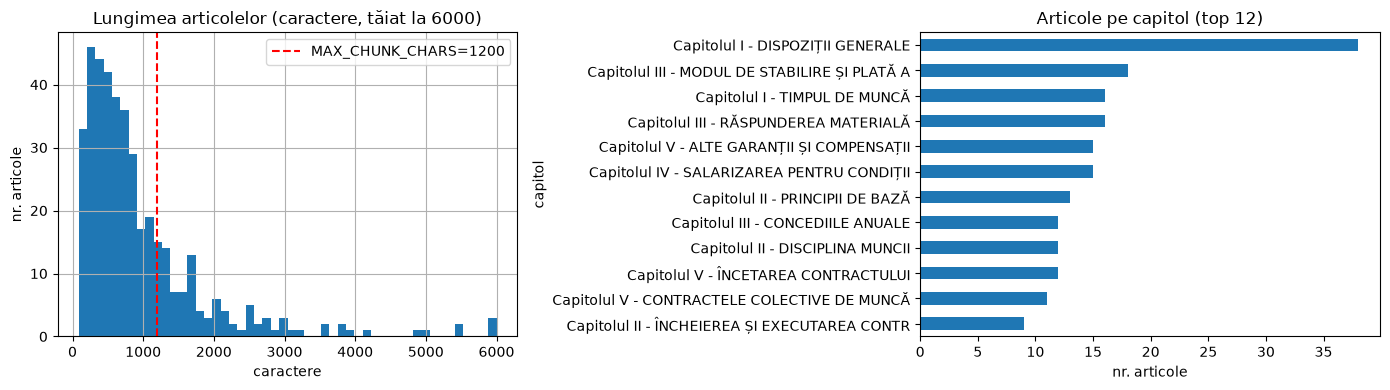


Cele mai lungi 5 articole:


,art_nr,art_titlu,n_chars
0,1,Noțiuni principale,11572
44,42^1,Informarea și consultarea salariaților,5950
11,9,Drepturile și obligațiile de bază ale salariatului,5897
10,8^2,"Procedura de raportare, investigare și de soluționare a cazurilor de violență și hărțuire în muncă",5477
92,86,Concedierea,5422


Cele mai scurte 5 articole:


,art_nr,art_titlu,n_chars
245,221,Încetarea (desfacerea) contractului de ucenicie,85
168,154,Salarizarea instructorilor și ucenicilor,88
88,82^1,Încetarea contractului individual de muncă prin acordul scris a părților,93
83,79,Modul de soluționare a litigiilor legate de suspendare ai contractului individual de muncă,114
377,351,Organele de jurisdicție a muncii,115


Salvat: /home/ivan/tmp/new/llm/laborator_2/data/processed/articole.csv


In [36]:
df_active = df_articles[~df_articles["abrogat"]].reset_index(drop=True)
print(f"Articole active (neabrogate): {len(df_active)}")
print(df_active["n_chars"].describe().round(0).to_string())

over = (df_active["n_chars"] > MAX_CHUNK_CHARS).mean()
print(f"\nArticole mai lungi decât MAX_CHUNK_CHARS={MAX_CHUNK_CHARS}: {over:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_active["n_chars"].clip(upper=6000).hist(bins=50, ax=axes[0])
axes[0].axvline(MAX_CHUNK_CHARS, color="red", ls="--", label=f"MAX_CHUNK_CHARS={MAX_CHUNK_CHARS}")
axes[0].set(title="Lungimea articolelor (caractere, tăiat la 6000)", xlabel="caractere", ylabel="nr. articole")
axes[0].legend()

per_cap = df_active["capitol"].str.slice(0, 45).value_counts().head(12)
per_cap.sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Articole pe capitol (top 12)", xlabel="nr. articole")
plt.tight_layout()
plt.show()

print("\nCele mai lungi 5 articole:")
display(df_active.nlargest(5, "n_chars")[["art_nr", "art_titlu", "n_chars"]])
print("Cele mai scurte 5 articole:")
display(df_active.nsmallest(5, "n_chars")[["art_nr", "art_titlu", "n_chars"]])

df_articles.drop(columns=["sort_key"]).to_csv(ARTICLES_CSV, index=False)
print(f"Salvat: {ARTICLES_CSV}")

## 6. Chunking

### 6.1 Teorie
Un **chunk** este unitatea pe care o indexăm și o returnăm la căutare. Dimensiunea lui e un compromis:

| Chunk prea mic | Chunk prea mare |
|---|---|
| pierde contextul (un alineat fără titlul articolului) | embedding-ul „medie” a prea multe idei devine vag |
| răspunsul e împărțit în multe bucăți | depășește limita modelului (512 tokeni la e5) și se trunchiază |

Comparăm două strategii:
- **A. Chunking fix (baseline):** ferestre de `FIXED_CHUNK_SIZE` caractere cu suprapunere `FIXED_CHUNK_OVERLAP`. E simplu, dar ignoră structura și taie articolele la mijloc;
- **B. Chunking structural (principal):** **un articol = un chunk**. Articolele lungi se împart pe **alineate** `(1)`, `(2)`... și, la nevoie, pe propoziții. Fiecare chunk primește un **antet contextual**:
  `Codul muncii al RM | Capitolul ... | Art. 112. Concediul de odihnă anual`
  Antetul ajută ambele căutări: BM25 găsește numărul și titlul articolului, iar embedding-ul „știe” despre ce e fragmentul chiar dacă e al 3-lea alineat.

### 6.2 Împărțirea articolelor lungi
Funcția `pack_units` grupează lacom unități consecutive (alineate sau propoziții) până la limita de caractere. O unitate prea mare e împărțită recursiv: alineat → propoziții → tăiere fixă, ca ultimă soluție.

In [37]:
ALINEAT_SPLIT_RE = re.compile(r"(?m)^(?=\(\d+(?:\^\d+)?\)\s)")   # început de linie cu „(n) ”
SENT_SPLIT_RE = re.compile(r"(?<=[.;:])\s+")


def split_oversized(unit: str, max_chars: int) -> list:
    sentences = [s for s in SENT_SPLIT_RE.split(unit) if s.strip()]
    if len(sentences) > 1:
        return pack_units(sentences, max_chars)
    return [unit[i:i + max_chars] for i in range(0, len(unit), max_chars)]


def pack_units(units: list, max_chars: int) -> list:
    parts, buf = [], ""
    for u in units:
        u = u.strip()
        if not u:
            continue
        if len(u) > max_chars:
            if buf:
                parts.append(buf)
                buf = ""
            parts.extend(split_oversized(u, max_chars))
            continue
        if buf and len(buf) + 1 + len(u) > max_chars:
            parts.append(buf)
            buf = u
        else:
            buf = f"{buf}\n{u}" if buf else u
    if buf:
        parts.append(buf)
    return parts


def split_article(text: str, max_chars: int) -> list:
    if len(text) <= max_chars:
        return [text]
    alineate = [a for a in ALINEAT_SPLIT_RE.split(text) if a.strip()]
    return pack_units(alineate, max_chars)


# Demonstrație pe cel mai lung articol
longest = df_active.loc[df_active["n_chars"].idxmax()]
demo_parts = split_article(longest["text"], MAX_CHUNK_CHARS)
print(f"Art. {longest['art_nr']} ({longest['n_chars']} caractere) → {len(demo_parts)} părți: "
      f"{[len(p) for p in demo_parts]}")

Art. 1 (11572 caractere) → 11 părți: [1132, 1019, 907, 1061, 1178, 975, 1179, 1143, 1045, 775, 1148]


### 6.3 Strategia B: chunking structural (principal)

In [38]:
def make_header(row, part: int, n_parts: int) -> str:
    pieces = ["Codul muncii al RM"]
    if row.capitol:
        pieces.append(row.capitol)
    art = f"Art. {row.art_nr}. {row.art_titlu}".strip()
    if n_parts > 1:
        art += f" (partea {part}/{n_parts})"
    pieces.append(art)
    return " | ".join(pieces)


def build_structural_chunks(df: pd.DataFrame, max_chars: int, with_header: bool = True) -> list:
    chunks = []
    for row in df.itertuples(index=False):
        parts = split_article(row.text, max_chars) if row.text else [row.art_titlu]
        for i, body in enumerate(parts, start=1):
            header = make_header(row, i, len(parts))
            chunks.append({
                "chunk_id": f"art{row.art_nr}-p{i}",
                "text": f"{header}\n{body}" if with_header else body,
                "body": body,
                "art_nr": row.art_nr,
                "art_titlu": row.art_titlu,
                "capitol": row.capitol,
                "part": i,
                "n_parts": len(parts),
                "articles": [row.art_nr],       # articolele acoperite (folosit la evaluare)
                "strategy": "structural",
            })
    return chunks


structural_chunks = build_structural_chunks(df_active, MAX_CHUNK_CHARS)
print(f"Chunk-uri structurale: {len(structural_chunks)} (din {len(df_active)} articole)")
print("\nExemplu de chunk:\n" + "-" * 60)
print(structural_chunks[min(10, len(structural_chunks) - 1)]["text"])

Chunk-uri structurale: 589 (din 409 articole)

Exemplu de chunk:
------------------------------------------------------------
Codul muncii al RM | Capitolul I - DISPOZIȚII INTRODUCTIVE | Art. 1. Noțiuni principale (partea 11/11)
utilizator de muncă temporară (denumit în continuare și utilizator) - persoana fizică ce desfășoară o activitate de întreprinzător sau întreprinderea, instituția sau organizația cu statut de persoană juridică, indiferent de tipul de proprietate, de forma juridică de organizare și de subordonarea departamentală sau apartenența ramurală, pentru care și sub supravegherea și conducerea căreia muncește temporar un salariat temporar pus la dispoziție de un agent de muncă temporară;
violență în muncă - orice comportament, acțiune, faptă, omisiune sau amenințare, săvârșită, o singură dată sau în mod repetat, în cadrul raporturilor de muncă, precum și în cadrul altor raporturi legate nemijlocit de acestea, care are ca scop și/sau efect vătămarea integrității fizice, psi

### 6.4 Strategia A: chunking fix (baseline)
Reconstruim textul integral și reținem **poziția fiecărui articol**. Un chunk fix poate acoperi **mai multe articole**, iar lista `articles` le reține pe toate. O vom folosi la evaluare.

In [39]:
def build_fixed_chunks(df: pd.DataFrame, size: int, overlap: int) -> list:
    pieces, spans, pos = [], [], 0
    for row in df.itertuples(index=False):
        block = f"Articolul {row.art_nr}. {row.art_titlu}\n{row.text}\n\n"
        spans.append((pos, pos + len(block), row.art_nr, row.art_titlu, row.capitol))
        pieces.append(block)
        pos += len(block)
    full = "".join(pieces)

    chunks, start, i = [], 0, 0
    while start < len(full):
        end = min(start + size, len(full))
        covered = [s for s in spans if s[0] < end and s[1] > start]
        body = full[start:end].strip()
        chunks.append({
            "chunk_id": f"fix-{i}",
            "text": body,
            "body": body,
            "art_nr": covered[0][2],
            "art_titlu": covered[0][3],
            "capitol": covered[0][4],
            "part": 1,
            "n_parts": 1,
            "articles": [s[2] for s in covered],
            "strategy": "fixed",
        })
        if end == len(full):
            break
        start, i = end - overlap, i + 1
    return chunks


fixed_chunks = build_fixed_chunks(df_active, FIXED_CHUNK_SIZE, FIXED_CHUNK_OVERLAP)
print(f"Chunk-uri fixe: {len(fixed_chunks)}")

Chunk-uri fixe: 507


### 6.5 Comparație între cele două strategii
Problema chunking-ului fix se vede imediat: fragmentele încep în mijlocul unei propoziții și amestecă articole diferite.

,strategie,nr_chunks,lungime_medie,lungime_max,chunks_cu_>1_articol
0,A. fix,507,998.0,1000,353
1,B. structural,589,816.0,1417,0


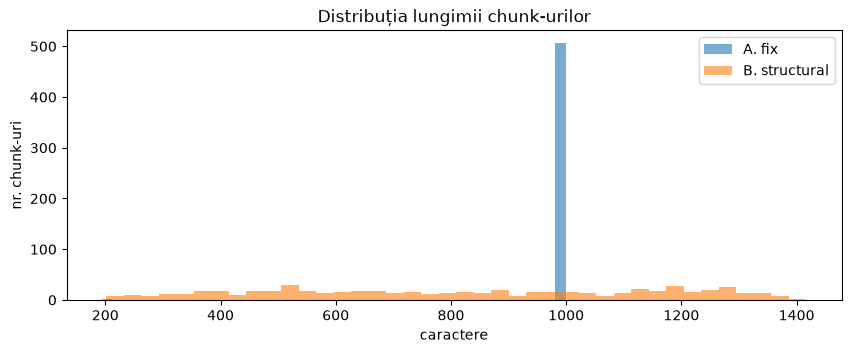

Exemplu de chunk fix care amestecă articolele ['1', '2']:
------------------------------------------------------------
mod repetat, în cadrul raporturilor de muncă, precum și în cadrul altor raporturi legate nemijlocit de acestea, care are ca scop și/sau efect vătămarea integrității fizice, psihice, sexuale sau economice a unei persoane. Violența în muncă include, în mod expres, agresiunea fizică, intimidarea, constrângerea, abuzul verbal sau psihologic, violența sexuală, violența digitală, precum și orice altă formă de comportament care lezează demnitatea, sănătatea sau securitatea persoanei, indiferent dacă este exercitată de către angajator, salariat ori terți.

Articolul 2. Reglementarea raporturilor de muncă și a altor raporturi legate nemijlocit de acestea
(1) Prezentul cod reglementează totalitatea ra


In [40]:
cmp = pd.DataFrame({
    "strategie": ["A. fix", "B. structural"],
    "nr_chunks": [len(fixed_chunks), len(structural_chunks)],
    "lungime_medie": [np.mean([len(c["text"]) for c in fixed_chunks]),
                      np.mean([len(c["text"]) for c in structural_chunks])],
    "lungime_max": [max(len(c["text"]) for c in fixed_chunks),
                    max(len(c["text"]) for c in structural_chunks)],
    "chunks_cu_>1_articol": [sum(len(c["articles"]) > 1 for c in fixed_chunks),
                             sum(len(c["articles"]) > 1 for c in structural_chunks)],
}).round(0)
display(cmp)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist([len(c["text"]) for c in fixed_chunks], bins=40, alpha=0.6, label="A. fix")
ax.hist([len(c["text"]) for c in structural_chunks], bins=40, alpha=0.6, label="B. structural")
ax.set(title="Distribuția lungimii chunk-urilor", xlabel="caractere", ylabel="nr. chunk-uri")
ax.legend()
plt.show()

mixed = next((c for c in fixed_chunks if len(c["articles"]) >= 2), None)
if mixed:
    print(f"Exemplu de chunk fix care amestecă articolele {mixed['articles']}:\n" + "-" * 60)
    print(mixed["text"][:700])

### 6.6 Salvarea chunk-urilor
Strategia **B (structurală)** devine colecția principală, `chunks`. Strategia A o folosim doar la ablații (12.5).

In [41]:
chunks = structural_chunks
with CHUNKS_JSONL.open("w", encoding="utf-8") as f:
    for c in chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
print(f"Salvat: {CHUNKS_JSONL} ({len(chunks)} chunk-uri)")

Salvat: /home/ivan/tmp/new/llm/laborator_2/data/processed/chunks.jsonl (589 chunk-uri)


## 7. Embeddings (reprezentări dense)

### 7.1 Teorie
Un **bi-encoder** transformă independent fiecare text într-un vector $\mathbf{e} \in \mathbb{R}^{d}$. Texte cu sens apropiat au vectori apropiați, chiar dacă folosesc cuvinte diferite („concediere” ≈ „a da afară”). Similaritatea se măsoară cu **cosinusul**:

$$\cos(\mathbf{q}, \mathbf{d}) = \frac{\mathbf{q} \cdot \mathbf{d}}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d} \rVert}$$

Dacă normalizăm vectorii ($\lVert \mathbf{e} \rVert = 1$), cosinusul devine un simplu **produs scalar**. Vom verifica asta manual în 8.4.

### 7.2 Modelul ales: `intfloat/multilingual-e5-base`
- multilingv, cu rezultate bune pe română (modelele `all-MiniLM-*` sunt antrenate aproape doar pe engleză);
- $d = 768$, cu o limită de 512 tokeni;
- a fost antrenat **asimetric**: întrebările primesc prefixul `query: `, iar documentele `passage: `. Fără prefixe, calitatea scade vizibil.

In [42]:
t0 = time.time()
embedder = SentenceTransformer(EMBED_MODEL_NAME, device=DEVICE)
EMBED_DIM = embedder.get_embedding_dimension()
print(f"Model încărcat în {time.time() - t0:.1f}s | dimensiune: {EMBED_DIM} | "
      f"lungime maximă: {embedder.max_seq_length} tokeni")

# Câți tokeni au chunk-urile? (verificăm că nu depășim limita modelului)
tok_lens = [len(embedder.tokenizer(PASSAGE_PREFIX + c["text"])["input_ids"]) for c in chunks]
print(f"Tokeni per chunk: medie {np.mean(tok_lens):.0f}, max {max(tok_lens)}, "
      f"peste {embedder.max_seq_length}: {sum(t > embedder.max_seq_length for t in tok_lens)}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model încărcat în 2.8s | dimensiune: 768 | lungime maximă: 512 tokeni
Tokeni per chunk: medie 205, max 363, peste 512: 0


### 7.3 Calculul embeddings-urilor (cu cache)
Pe CPU, calculul pentru câteva sute de chunk-uri durează de la zeci de secunde la câteva minute. Salvăm matricea în `cache/` sub o cheie care depinde de **model + prefix + textul chunk-urilor**. Dacă se schimbă chunking-ul, cheia se schimbă și embeddings-urile se recalculează automat.

In [43]:
def fingerprint(texts: list, *extra: str) -> str:
    h = hashlib.sha256()
    for e in extra:
        h.update(e.encode("utf-8"))
    for t in texts:
        h.update(t.encode("utf-8"))
        h.update(b"\x00")
    return h.hexdigest()[:16]


def embed_passages(texts: list, name: str) -> np.ndarray:
    path = CACHE_DIR / f"emb_{name}_{fingerprint(texts, EMBED_MODEL_NAME, PASSAGE_PREFIX)}.npy"
    if path.exists():
        print(f"[{name}] embeddings încărcate din cache: {path.name}")
        return np.load(path)
    t0 = time.time()
    emb = embedder.encode(
        [PASSAGE_PREFIX + t for t in texts],
        batch_size=32,
        normalize_embeddings=True,     # ||e|| = 1 → cosinus = produs scalar
        show_progress_bar=True,
        convert_to_numpy=True,
    ).astype(np.float32)
    np.save(path, emb)
    print(f"[{name}] {len(texts)} embeddings calculate în {time.time() - t0:.1f}s → {path.name}")
    return emb


def embed_query(query: str) -> np.ndarray:
    return embedder.encode(QUERY_PREFIX + query, normalize_embeddings=True,
                           convert_to_numpy=True).astype(np.float32)


chunk_embeddings = embed_passages([c["text"] for c in chunks], "structural")

[structural] embeddings încărcate din cache: emb_structural_edcb49852cec88db.npy


### 7.4 Verificări
1. forma matricei: `(nr_chunks, 768)`;
2. normele vectorilor sunt egale cu 1;
3. **test semantic:** două fraze cu același sens și cuvinte diferite trebuie să aibă similaritatea mai mare decât o frază fără legătură.

In [44]:
norms = np.linalg.norm(chunk_embeddings, axis=1)
print(f"Formă: {chunk_embeddings.shape} | norme: min={norms.min():.4f}, max={norms.max():.4f}")

sentences = [
    "Salariatul are dreptul la concediu de odihnă anual plătit.",
    "Angajatul poate lua în fiecare an o vacanță pentru care este plătit.",
    "Angajatorul poate aplica sancțiuni disciplinare pentru încălcarea disciplinei.",
]
E = embedder.encode([PASSAGE_PREFIX + s for s in sentences], normalize_embeddings=True)
sim = pd.DataFrame(E @ E.T, index=["S1 concediu", "S2 vacanță", "S3 sancțiuni"],
                   columns=["S1", "S2", "S3"]).round(3)
display(sim)
print("Așteptat: sim(S1, S2) > sim(S1, S3), deși S1 și S2 au foarte puține cuvinte comune.")

Formă: (589, 768) | norme: min=1.0000, max=1.0000


,S1,S2,S3
S1 concediu,1.000,0.931,0.883
S2 vacanță,0.931,1.000,0.901
S3 sancțiuni,0.883,0.901,1.000


Așteptat: sim(S1, S2) > sim(S1, S3), deși S1 și S2 au foarte puține cuvinte comune.


## 8. Indexul vectorial: Qdrant în memorie

### 8.1 De ce Qdrant `:memory:`
- rulează **în procesul Python**, fără Docker și fără server; profesorul dă *Run All* și merge;
- pentru câteva sute de vectori căutarea durează sub o milisecundă;
- stochează **payload-ul** (textul și metadatele) lângă vector, deci căutarea returnează direct articolul.

Pașii sunt expliciți: **creăm colecția** (dimensiune și metrică) → **construim punctele** (`PointStruct`: id, vector, payload) → **`upsert`**.

In [45]:
qdrant = QdrantClient(":memory:")


def create_dense_collection(name: str, embeddings: np.ndarray, chunk_list: list) -> None:
    # 1) colecție nouă: dimensiunea vectorilor + metrica cosinus
    if qdrant.collection_exists(name):
        qdrant.delete_collection(name)
    qdrant.create_collection(
        collection_name=name,
        vectors_config=VectorParams(size=embeddings.shape[1], distance=Distance.COSINE),
    )
    # 2) punctele: id = poziția chunk-ului în listă, payload = metadate pentru afișare
    points = [
        PointStruct(
            id=i,
            vector=embeddings[i].tolist(),
            payload={
                "chunk_id": c["chunk_id"],
                "art_nr": c["art_nr"],
                "art_titlu": c["art_titlu"],
                "articles": c["articles"],
                "text": c["text"],
            },
        )
        for i, c in enumerate(chunk_list)
    ]
    # 3) inserarea
    qdrant.upsert(collection_name=name, points=points, wait=True)
    print(f"Colecția '{name}': {qdrant.count(name).count} puncte, dim={embeddings.shape[1]}, cosinus")


create_dense_collection(COLLECTION_MAIN, chunk_embeddings, chunks)

Colecția 'codul_muncii_structural': 589 puncte, dim=768, cosinus


### 8.2 Căutarea densă
Vectorizăm întrebarea (cu prefixul `query: `) și cerem de la Qdrant cei mai apropiați `limit` vectori. Returnăm perechi `(index_chunk, scor_cosinus)`.

In [46]:
def dense_search(query: str, collection: str, limit: int) -> list:
    qv = embed_query(query)
    res = qdrant.query_points(collection_name=collection, query=qv.tolist(),
                              limit=limit, with_payload=False)
    return [(int(p.id), float(p.score)) for p in res.points]


q_demo = "Câte zile de concediu de odihnă anual are salariatul?"
print(f"Întrebare: {q_demo}\n")
for rank, (i, s) in enumerate(dense_search(q_demo, COLLECTION_MAIN, 5), start=1):
    print(f"{rank}. [cos={s:.4f}] Art. {chunks[i]['art_nr']}. {chunks[i]['art_titlu']}")

Întrebare: Câte zile de concediu de odihnă anual are salariatul?

1. [cos=0.9027] Art. 113. Durata concediului de odihnă anual
2. [cos=0.8909] Art. 113^1. Anul de muncă pentru care se acordă concediul de odihnă anual
3. [cos=0.8890] Art. 115. Modul de acordare a concediului de odihnă anual
4. [cos=0.8836] Art. 118. Acordarea anuală a concediului de odihnă. Cazurile excepționale de amânare a acestuia
5. [cos=0.8822] Art. 116. Programarea concediilor de odihnă anuale


### 8.3 Verificarea manuală a lui Qdrant cu NumPy
Ca Qdrant să nu fie o „cutie neagră”, refacem căutarea **de mână**. Vectorii sunt normalizați, deci similaritatea cosinus este produsul matrice–vector:

$$\mathbf{s} = E\,\mathbf{q}, \qquad E \in \mathbb{R}^{N \times d},\ \mathbf{q} \in \mathbb{R}^{d}$$

Sortăm descrescător și comparăm cu rezultatul Qdrant: **ID-urile** trebuie să fie identice, iar **scorurile** egale până la erori numerice de ordinul $10^{-6}$.

In [47]:
qv = embed_query(q_demo)
scores_np = chunk_embeddings @ qv                       # cosinus pentru toate chunk-urile deodată
top_np = np.argsort(-scores_np)[:10]
top_qd = dense_search(q_demo, COLLECTION_MAIN, 10)

verif = pd.DataFrame({
    "rang": range(1, 11),
    "id_numpy": top_np,
    "scor_numpy": scores_np[top_np].round(6),
    "id_qdrant": [i for i, _ in top_qd],
    "scor_qdrant": [round(s, 6) for _, s in top_qd],
})
verif["identic"] = verif["id_numpy"] == verif["id_qdrant"]
display(verif)

max_diff = np.max(np.abs(scores_np[[i for i, _ in top_qd]] - np.array([s for _, s in top_qd])))
print(f"Aceeași ordine: {verif['identic'].all()} | diferența maximă de scor: {max_diff:.2e}")

,rang,id_numpy,scor_numpy,id_qdrant,scor_qdrant,identic
0,1,228,0.902660,228,0.902660,True
1,2,229,0.890893,229,0.890894,True
2,3,233,0.889029,233,0.889029,True
3,4,237,0.883627,237,0.883627,True
4,5,235,0.882209,235,0.882209,True
5,6,243,0.881370,243,0.881370,True
6,7,461,0.880541,461,0.880541,True
7,8,238,0.878929,238,0.878929,True
8,9,240,0.878400,240,0.878400,True
9,10,239,0.878101,239,0.878101,True


Aceeași ordine: True | diferența maximă de scor: 1.41e-07


## 9. Indexul lexical: BM25

### 9.1 Teorie
BM25 e o evoluție a TF-IDF: punctează documentele care conțin **exact cuvintele** din întrebare, cu ponderi mai mari pentru cuvintele rare:

$$\text{BM25}(D, Q) = \sum_{t \in Q} \text{IDF}(t)\cdot\frac{f(t, D)\,(k_1 + 1)}{f(t, D) + k_1\left(1 - b + b\,\frac{|D|}{\text{avgdl}}\right)}$$

- $f(t, D)$ este frecvența termenului în document; $k_1 \approx 1.5$ controlează saturația frecvenței;
- $b \approx 0.75$ penalizează documentele lungi.

**Puncte forte:** termeni exacți, numere de articole, jargon juridic. **Puncte slabe:** nu înțelege sinonimele („concediere” ≠ „a da afară”).

### 9.2 Tokenizarea pentru română
1. litere mici, apoi `â → î` și eliminarea diacriticelor cu `unidecode`. Oamenii scriu des fără diacritice, iar Codul folosește ortografia veche („sînt”, „cîte”);
2. maparea `sunt → sint`, ca forma modernă să corespundă celei din lege;
3. eliminarea cuvintelor de legătură foarte frecvente (*stopwords*), dar **păstrarea numerelor** (inclusiv cele dintr-o singură cifră, de exemplu „art. 7”).

In [49]:
STOPWORDS_RO = {
    "si", "de", "la", "in", "cu", "pe", "din", "al", "ale", "ai", "sau", "ca", "care", "ce",
    "se", "un", "o", "unei", "unui", "este", "sint", "fi", "prin", "pentru", "sa", "mai",
    "dupa", "catre", "fara", "daca", "acest", "aceasta", "acestui", "acestei", "lui", "lor",
    "cel", "cea", "cei", "cele", "am", "are", "au", "fost", "iar", "dar", "ori", "cit", "cita",
}
ORTHO_MAP = {"sunt": "sint", "suntem": "sintem", "sunteti": "sinteti"}


def tokenize_ro(text: str) -> list:
    text = unidecode(text.lower().replace("â", "î"))
    tokens = (ORTHO_MAP.get(t, t) for t in re.findall(r"[a-z0-9]+", text))
    return [t for t in tokens if t not in STOPWORDS_RO and (len(t) > 1 or t.isdigit())]


print(tokenize_ro("Câți ani sunt necesari? Conform art. 7, salariații își pot exercita dreptul..."))

['citi', 'ani', 'necesari', 'conform', 'art', '7', 'salariatii', 'isi', 'pot', 'exercita', 'dreptul']


### 9.3 Construirea indexului BM25
Indexăm **același text** ca la embeddings (cu antetul), deci și numărul și titlul articolului devin căutabile.

In [50]:
def build_bm25(chunk_list: list) -> BM25Okapi:
    return BM25Okapi([tokenize_ro(c["text"]) for c in chunk_list], k1=1.5, b=0.75)


def sparse_search(query: str, bm25: BM25Okapi, limit: int) -> list:
    scores = bm25.get_scores(tokenize_ro(query))
    top = np.argsort(-scores)[:limit]
    return [(int(i), float(scores[i])) for i in top if scores[i] > 0]   # scor 0 = niciun termen comun


bm25 = build_bm25(chunks)
print(f"Index BM25 construit pe {len(chunks)} chunk-uri, "
      f"vocabular: {len(bm25.idf)} termeni, lungime medie: {bm25.avgdl:.0f} tokeni")

for q in ["preaviz", "perioada de probă", "articolul 112"]:
    print(f"\nBM25 → '{q}'")
    for rank, (i, s) in enumerate(sparse_search(q, bm25, 3), start=1):
        print(f"  {rank}. [bm25={s:.2f}] Art. {chunks[i]['art_nr']}. {chunks[i]['art_titlu']}")

Index BM25 construit pe 589 chunk-uri, vocabular: 5105 termeni, lungime medie: 80 tokeni

BM25 → 'preaviz'
  1. [bm25=4.78] Art. 48. Informarea privind condițiile de activitate
  2. [bm25=4.37] Art. 49. Conținutul contractului individual de muncă

BM25 → 'perioada de probă'
  1. [bm25=11.57] Art. 60. Perioada de probă
  2. [bm25=8.40] Art. 61. Perioada de probă a salariaților angajați în baza contractului individual de muncă pe durată determinată
  3. [bm25=7.97] Art. 63. Rezultatul perioadei de probă

BM25 → 'articolul 112'
  1. [bm25=5.75] Art. 112. Concediul de odihnă anual
  2. [bm25=4.98] Art. 81. Temeiurile încetării contractului individual de muncă
  3. [bm25=3.86] Art. 124. Concediul de maternitate și concediul parțial plătit pentru îngrijirea copilului


## 10. Cele trei metode de retrieval

Grupăm tot ce ține de un index (chunk-uri, embeddings, colecția Qdrant, BM25) într-o structură simplă, `RAGIndex`. Așa putem rula aceleași metode și pe indexurile alternative de la ablații (12.5).

In [51]:
@dataclass
class RAGIndex:
    name: str
    chunks: list
    embeddings: np.ndarray
    collection: str
    bm25: BM25Okapi


main_index = RAGIndex("structural", chunks, chunk_embeddings, COLLECTION_MAIN, bm25)


def make_result(index: RAGIndex, chunk_idx: int, score: float, rank: int, **extra) -> dict:
    c = index.chunks[chunk_idx]
    return {"rank": rank, "chunk_idx": chunk_idx, "score": score, "chunk_id": c["chunk_id"],
            "art_nr": c["art_nr"], "art_titlu": c["art_titlu"], "articles": c["articles"],
            "text": c["text"], **extra}


def results_df(results: list) -> pd.DataFrame:
    cols = [c for c in ["rank", "art_nr", "art_titlu", "score", "dense_rank", "bm25_rank",
                        "rrf_rank", "rrf_score"] if c in results[0]] if results else []
    return pd.DataFrame(results)[cols].round(4)

### 10.1 Metoda 1: Naive RAG
Doar căutarea densă: cei mai apropiați `k` vectori.

In [52]:
def naive_search(query: str, index: RAGIndex, k: int = TOP_K) -> list:
    hits = dense_search(query, index.collection, k)
    return [make_result(index, i, s, r) for r, (i, s) in enumerate(hits, start=1)]


display(results_df(naive_search("Pot fi concediat în timp ce sunt în concediu medical?", main_index)))

,rank,art_nr,art_titlu,score
0,1,86,Concedierea,0.8683
1,2,194,Garanții în legătură cu concediul medical,0.8644
2,3,118,Acordarea anuală a concediului de odihnă. Cazurile excepționale de amânare a acestuia,0.8609
3,4,117,Indemnizația de concediu,0.8529
4,5,118,Acordarea anuală a concediului de odihnă. Cazurile excepționale de amânare a acestuia,0.8520


### 10.2 Metoda 2: Hybrid RAG (BM25 + dense + RRF)

Scorurile celor două sisteme **nu sunt comparabile**: cosinusul e în $[-1, 1]$, iar BM25 e nemărginit. **Reciprocal Rank Fusion** ignoră scorurile și folosește doar **rangurile**:

$$\text{RRF}(d) = \sum_{m \in \{\text{dense},\,\text{BM25}\}} \frac{1}{k + r_m(d)}$$

- $r_m(d)$ este poziția documentului $d$ în lista metodei $m$ (1 = primul). Dacă documentul lipsește din listă, termenul lipsește;
- $k = 60$ (valoarea din articolul original, Cormack et al., 2009) „netezește” diferențele dintre primele poziții: locul 1 dă $1/61 \approx 0.0164$, locul 10 dă $1/70 \approx 0.0143$;
- un document găsit de **ambele** metode primește două contribuții, deci urcă în clasament.

In [53]:
def reciprocal_rank_fusion(ranked_lists: list, k: int = K_RRF) -> list:
    """ranked_lists: liste de id-uri ordonate descrescător după relevanță.
    Returnează [(id, scor_rrf)] sortat descrescător."""
    scores = {}
    for ranked in ranked_lists:
        for rank, doc_id in enumerate(ranked, start=1):
            scores[doc_id] = scores.get(doc_id, 0.0) + 1.0 / (k + rank)
    return sorted(scores.items(), key=lambda kv: kv[1], reverse=True)


def hybrid_search(query: str, index: RAGIndex, k: int = TOP_K,
                  candidates: int = CANDIDATES, k_rrf: int = K_RRF) -> list:
    dense_ids = [i for i, _ in dense_search(query, index.collection, candidates)]
    sparse_ids = [i for i, _ in sparse_search(query, index.bm25, candidates)]
    fused = reciprocal_rank_fusion([dense_ids, sparse_ids], k=k_rrf)

    dense_rank = {i: r for r, i in enumerate(dense_ids, start=1)}
    sparse_rank = {i: r for r, i in enumerate(sparse_ids, start=1)}
    return [make_result(index, i, s, r, dense_rank=dense_rank.get(i), bm25_rank=sparse_rank.get(i))
            for r, (i, s) in enumerate(fused[:k], start=1)]


# Mini-exemplu numeric (verificabil de mână)
print("Exemplu didactic:", reciprocal_rank_fusion([["A", "B", "C"], ["C", "A", "D"]], k=60))
print("A: 1/61 + 1/62 | C: 1/63 + 1/61 | B: 1/62 | D: 1/63\n")

Exemplu didactic: [('A', 0.03252247488101534), ('C', 0.032266458495966696), ('B', 0.016129032258064516), ('D', 0.015873015873015872)]
A: 1/61 + 1/62 | C: 1/63 + 1/61 | B: 1/62 | D: 1/63



**Tabel didactic:** pentru o întrebare, vedem rangul fiecărui fragment în fiecare sistem și scorul RRF rezultat. Cele găsite de ambele sisteme urcă; `None` înseamnă că sistemul respectiv nu l-a găsit în top-20.

In [54]:
q_rrf = "Cu cât timp înainte trebuie să anunț angajatorul că vreau să plec?"
print(f"Întrebare: {q_rrf}")
display(results_df(hybrid_search(q_rrf, main_index, k=10)))

Întrebare: Cu cât timp înainte trebuie să anunț angajatorul că vreau să plec?


,rank,art_nr,art_titlu,score,dense_rank,bm25_rank
0,1,97^1,Garanții pentru salariații cu timp de muncă parțial,0.0313,7.0,1.0
1,2,55^1,Garanții pentru salariații angajați pe o durată determinată,0.0293,16.0,2.0
2,3,85,Demisia,0.0292,11.0,6.0
3,4,278,Încetarea contractului individual de muncă,0.0284,13.0,8.0
4,5,42^1,Informarea și consultarea salariaților,0.0278,10.0,14.0
5,6,184,Garanții în caz de încetare a contractului individual de muncă,0.0274,8.0,19.0
6,7,185^1,Garanții în caz de concedieri colective,0.0164,1.0,NaN
7,8,85,Demisia,0.0161,2.0,NaN
8,9,42^1,Informarea și consultarea salariaților,0.0159,3.0,NaN
9,10,42^1,Informarea și consultarea salariaților,0.0159,NaN,3.0


### 10.3 Metoda 3: Advanced RAG (RRF + re-ranking cu cross-encoder)

| Bi-encoder (embeddings) | Cross-encoder (re-ranker) |
|---|---|
| întrebarea și documentul sunt codificate **separat** | perechea `(întrebare, document)` intră **împreună** în transformer |
| vectorii documentelor se calculează o singură dată → rapid | trebuie rulat pentru fiecare pereche → lent |
| atenția nu „vede” interacțiunea dintre cuvintele întrebării și ale documentului | atenție completă între toate cuvintele → relevanță mult mai precisă |

De aceea îl folosim **în cascadă**: RRF aduce rapid 15 candidați, iar cross-encoderul îi reordonează și păstrăm top-k. Modelul `BAAI/bge-reranker-v2-m3` e multilingv. Pe CPU durează câteva secunde per întrebare, de aceea limităm numărul de candidați.

In [55]:
t0 = time.time()
reranker = CrossEncoder(RERANK_MODEL_NAME, max_length=512, device=DEVICE)
print(f"Re-ranker încărcat în {time.time() - t0:.1f}s")


def rerank_search(query: str, index: RAGIndex, k: int = TOP_K,
                  n_candidates: int = RERANK_CANDIDATES) -> list:
    cands = hybrid_search(query, index, k=n_candidates)
    if not cands:
        return []
    pairs = [(query, c["text"]) for c in cands]
    scores = np.asarray(reranker.predict(pairs, batch_size=16, show_progress_bar=False))
    order = np.argsort(-scores)[:k]
    out = []
    for new_rank, j in enumerate(order, start=1):
        r = dict(cands[j])
        r.update(rank=new_rank, score=float(scores[j]), rrf_rank=cands[j]["rank"],
                 rrf_score=cands[j]["score"])
        out.append(r)
    return out


t0 = time.time()
rr = rerank_search(q_rrf, main_index, k=5)
print(f"Întrebare: {q_rrf}  ({time.time() - t0:.1f}s)")
display(results_df(rr))
print("Coloana rrf_rank arată de pe ce poziție a urcat (sau a coborât) fiecare fragment după re-ranking.")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Re-ranker încărcat în 1.8s
Întrebare: Cu cât timp înainte trebuie să anunț angajatorul că vreau să plec?  (9.5s)


,rank,art_nr,art_titlu,score,dense_rank,bm25_rank,rrf_rank,rrf_score
0,1,85,Demisia,0.6606,2,NaN,8,0.0161
1,2,278,Încetarea contractului individual de muncă,0.4035,13,8.0,4,0.0284
2,3,184,Garanții în caz de încetare a contractului individual de muncă,0.3460,8,19.0,6,0.0274
3,4,85,Demisia,0.3006,11,6.0,3,0.0292
4,5,185^1,Garanții în caz de concedieri colective,0.2219,4,NaN,11,0.0156


Coloana rrf_rank arată de pe ce poziție a urcat (sau a coborât) fiecare fragment după re-ranking.


### 10.4 Interfața comună și comparația dintre metode
Funcția `retrieve(query, method)` e punctul unic de intrare, folosit în generare, evaluare și chat.

In [56]:
METHODS = {"naive": naive_search, "hybrid": hybrid_search, "rerank": rerank_search}
METHOD_LABELS = {
    "naive": "Naive RAG (dense)",
    "hybrid": "Hybrid RAG (BM25 + dense + RRF)",
    "rerank": "Advanced RAG (RRF + re-ranking)",
}


def retrieve(query: str, method: str = "rerank", k: int = TOP_K, index: RAGIndex = None) -> list:
    return METHODS[method](query, index or main_index, k=k)


def compare_methods(query: str, k: int = 5) -> pd.DataFrame:
    cols = {}
    for m in METHODS:
        res = retrieve(query, m, k)
        cols[METHOD_LABELS[m]] = [f"Art. {r['art_nr']}. {r['art_titlu'][:40]}" for r in res] + [""] * (k - len(res))
    return pd.DataFrame(cols, index=range(1, k + 1))


for q in ["Ce prevede codul despre preaviz?",
          "Șeful mă ține peste program, trebuie să mă plătească mai mult?"]:
    print(f"\nÎntrebare: {q}")
    display(compare_methods(q))


Întrebare: Ce prevede codul despre preaviz?


,Naive RAG (dense),Hybrid RAG (BM25 + dense + RRF),Advanced RAG (RRF + re-ranking)
1,Art. 362. Declararea grevei,Art. 48. Informarea privind condițiile de activit,Art. 287. Încetarea contractului individual de mun
2,Art. 48. Informarea privind condițiile de activit,Art. 49. Conținutul contractului individual de mu,Art. 48. Informarea privind condițiile de activit
3,Art. 49. Conținutul contractului individual de mu,Art. 287. Încetarea contractului individual de mun,Art. 49. Conținutul contractului individual de mu
4,Art. 391.,Art. 362. Declararea grevei,Art. 278. Încetarea contractului individual de mun
5,Art. 287. Încetarea contractului individual de mun,Art. 323. Munca salariaților din unitățile militar,Art. 286. Modificarea clauzelor contractului indiv



Întrebare: Șeful mă ține peste program, trebuie să mă plătească mai mult?


,Naive RAG (dense),Hybrid RAG (BM25 + dense + RRF),Advanced RAG (RRF + re-ranking)
1,Art. 157. Retribuirea muncii suplimentare,Art. 104. Munca suplimentară,Art. 104. Munca suplimentară
2,Art. 104. Munca suplimentară,Art. 153. Retribuirea muncii în caz de efectuare a,Art. 159. Retribuirea muncii de noapte
3,Art. 148. Reținerile din salariu,Art. 158. Compensația pentru munca prestată în zil,Art. 131. Salariul minim
4,Art. 104. Munca suplimentară,Art. 10. Drepturile și obligațiile angajatorului,Art. 157. Retribuirea muncii suplimentare
5,Art. 146. Răspunderea pentru neachitarea la timp a,Art. 157. Retribuirea muncii suplimentare,Art. 158. Compensația pentru munca prestată în zil


## 11. Generarea răspunsului cu LLM

### 11.1 Clientul LLM
Ollama Cloud și OpenRouter expun ambele un API **compatibil OpenAI**, deci folosim biblioteca `openai` și schimbăm doar `base_url`, cheia și numele modelului (setate în cap. 2). Implicit: `gpt-oss:120b` prin Ollama Cloud (`https://ollama.com/v1`).

In [57]:
llm_client = OpenAI(base_url=LLM_CFG["base_url"], api_key=LLM_API_KEY or "lipsa-cheie",
                    timeout=120, max_retries=2)


def call_llm(messages: list, temperature: float = LLM_TEMPERATURE) -> str:
    if not LLM_API_KEY:
        raise RuntimeError(f"Lipsește cheia {LLM_CFG['api_key_env']} în .env")
    resp = llm_client.chat.completions.create(model=LLM_MODEL, messages=messages,
                                              temperature=temperature)
    return (resp.choices[0].message.content or "").strip()


# Test de conectivitate
try:
    t0 = time.time()
    print("Răspuns test:", call_llm([{"role": "user", "content": "Răspunde doar cu: OK"}]),
          f"({time.time() - t0:.1f}s)")
except Exception as exc:
    print(f"Conexiunea la LLM a eșuat: {type(exc).__name__}: {exc}")

Răspuns test: OK (0.5s)


### 11.2 Promptul de sistem
Promptul are rol de **contract** cu modelul:
1. răspunde **exclusiv** din context, nu din cunoștințele proprii;
2. **citează** articolele, ca răspunsul să poată fi verificat;
3. are o **formulă fixă de refuz** când informația lipsește (o detectăm automat la evaluare);
4. limbă, format și disclaimer.

In [58]:
REFUSAL_TEXT = "Nu găsesc această informație în fragmentele din Codul muncii pe care le am la dispoziție."

SYSTEM_PROMPT = f"""Ești un asistent educațional care răspunde la întrebări despre Codul muncii al Republicii Moldova (Legea nr. 154/2003).

Reguli:
1. Folosește EXCLUSIV informațiile din fragmentele din secțiunea CONTEXT. Nu folosi cunoștințe proprii despre lege.
2. Citează articolele pe care te bazezi, în forma „(art. N)”.
3. Dacă fragmentele nu conțin răspunsul, răspunde exact: „{REFUSAL_TEXT}” și nu încerca să ghicești.
4. Răspunde în limba română, clar și concis (cel mult 2-3 paragrafe sau o listă scurtă).
5. Nu oferi consultanță juridică; pentru situații concrete recomandă consultarea unui specialist."""


def format_context(results: list) -> str:
    return "\n\n".join(f"[Fragment {i}]\n{r['text']}" for i, r in enumerate(results, start=1))


def build_messages(question: str, results: list, history: list = None) -> list:
    user_msg = f"CONTEXT:\n{format_context(results)}\n\nÎNTREBARE: {question}"
    return [{"role": "system", "content": SYSTEM_PROMPT}, *(history or []),
            {"role": "user", "content": user_msg}]


print(build_messages("Exemplu de întrebare?", retrieve("concediu de odihnă", "naive", 2))[1]["content"][:800])

CONTEXT:
[Fragment 1]
Codul muncii al RM | Capitolul III - CONCEDIILE ANUALE | Art. 113. Durata concediului de odihnă anual
(1) Tuturor salariaților li se acordă anual un concediu de odihnă plătit, cu o durată minimă de 28 de zile calendaristice, cu excepția zilelor de sărbătoare nelucrătoare.
(2) Pentru salariații din unele ramuri ale economiei naționale (învățământ, ocrotirea sănătății, serviciul public etc.), prin lege organică, se poate stabili o altă durată a concediului de odihnă anual (calculată în zile calendaristice).

[Fragment 2]
Codul muncii al RM | Capitolul III - CONCEDIILE ANUALE | Art. 115. Modul de acordare a concediului de odihnă anual (partea 2/2)
(5) Concediul de odihnă anual poate fi acordat integral sau, în baza unei cereri scrise a salariatului, poate fi divizat în p


### 11.3 Pipeline-ul RAG complet
`rag_answer` = retrieval + construirea promptului + generare. Măsurăm separat timpul fiecărei etape.

In [59]:
def rag_answer(question: str, method: str = "rerank", k: int = TOP_K,
               index: RAGIndex = None, history: list = None) -> dict:
    t0 = time.time()
    results = retrieve(question, method, k, index)
    t1 = time.time()
    try:
        answer = call_llm(build_messages(question, results, history))
    except Exception as exc:
        answer = f"[Eroare LLM: {type(exc).__name__}: {exc}]"
    t2 = time.time()
    return {"question": question, "method": method, "answer": answer, "sources": results,
            "timings": {"retrieval_s": round(t1 - t0, 2), "generation_s": round(t2 - t1, 2)}}


def show_rag(out: dict) -> None:
    src = "\n".join(f"- Art. {r['art_nr']}. {r['art_titlu']} (scor {r['score']:.4f})" for r in out["sources"])
    display(Markdown(
        f"**{METHOD_LABELS[out['method']]}** · retrieval {out['timings']['retrieval_s']}s · "
        f"generare {out['timings']['generation_s']}s\n\n{out['answer']}\n\n**Surse:**\n{src}"
    ))

### 11.4 Demonstrație: aceeași întrebare prin toate cele trei metode

In [60]:
q_gen = "Mă poate concedia angajatorul cât timp sunt în concediu medical?"
display(Markdown(f"### Întrebare: {q_gen}"))
for m in METHODS:
    show_rag(rag_answer(q_gen, m))
    display(Markdown("---"))

### Întrebare: Mă poate concedia angajatorul cât timp sunt în concediu medical?

**Naive RAG (dense)** · retrieval 0.04s · generare 1.77s

Nu. Conform art. 86 alin. (2) din Codul muncii, concedierea nu se admite în perioada în care salariatul se află în concediu medical, cu excepția cazului de lichidare a unității (art. 86).  

Așadar, în mod normal angajatorul nu poate să te concedieze în timp ce ești în concediu medical; doar în situația în care unitatea este lichidată se aplică alte prevederi speciale.  

*Pentru situații concrete, este recomandat să consulţi un specialist în dreptul muncii.*

**Surse:**
- Art. 86. Concedierea (scor 0.8691)
- Art. 194. Garanții în legătură cu concediul medical (scor 0.8686)
- Art. 76^1. Activitatea de muncă în perioada aflării în concediu de maternitate (scor 0.8668)
- Art. 88. Procedura de concediere în cazul lichidării unității, reducerii numărului sau a statelor de personal (scor 0.8666)
- Art. 85. Demisia (scor 0.8642)

---

**Hybrid RAG (BM25 + dense + RRF)** · retrieval 0.04s · generare 1.21s

Nu. Conform art. 86 alin. (2) din Codul muncii, concedierea salariatului nu este admisă în perioada în care acesta se află în concediu medical (cu excepția cazurilor de lichidare a unității). (art. 86)  

Pentru situații concrete este recomandată consultarea unui specialist în dreptul muncii.

**Surse:**
- Art. 86. Concedierea (scor 0.0325)
- Art. 194. Garanții în legătură cu concediul medical (scor 0.0325)
- Art. 118. Acordarea anuală a concediului de odihnă. Cazurile excepționale de amânare a acestuia (scor 0.0306)
- Art. 120. Concediul neplătit (scor 0.0294)
- Art. 78. Suspendarea contractului individual de muncă la inițiativa uneia dintre părți (scor 0.0294)

---

**Advanced RAG (RRF + re-ranking)** · retrieval 9.76s · generare 2.04s

Nu. Conform art. 86 alin. (2) din Codul muncii „Nu se admite concedierea salariatului în perioada aflării lui în concediu medical …, cu excepția cazurilor de lichidare a unității” (art. 86). În plus, art. 88 alin. (2) prevede că în termenul de preavizare de 2 luni nu se includ zilele în care salariatul se află în concediu medical.  

Așadar, în timpul concediului medical nu poţi fi concediat, cu excepţia situaţiei de lichidare a unităţii. Pentru cazuri concrete, consultă un specialist în dreptul muncii.

**Surse:**
- Art. 86. Concedierea (scor 0.9503)
- Art. 88. Procedura de concediere în cazul lichidării unității, reducerii numărului sau a statelor de personal (scor 0.2718)
- Art. 194. Garanții în legătură cu concediul medical (scor 0.2693)
- Art. 118. Acordarea anuală a concediului de odihnă. Cazurile excepționale de amânare a acestuia (scor 0.1823)
- Art. 60. Perioada de probă (scor 0.1076)

---

## 12. Evaluare

O comparație „din ochi” nu e suficientă, așa că măsurăm.

### 12.1 Setul de test
Întrebările sunt de trei tipuri:
- **exact:** folosesc termenii din lege (avantaj pentru BM25);
- **parafrază:** limbaj colocvial, alte cuvinte decât legea (avantaj pentru căutarea densă);
- **capcană:** în afara Codului muncii; sistemul trebuie să refuze.

**Răspunsul corect** e definit prin **cuvinte-cheie din titlul articolului**, nu prin numere scrise de mână. Celula următoare le rezolvă automat în numere de articol, pe textul real descărcat, și le afișează pentru verificare. Dacă o întrebare nu găsește niciun articol sau găsește articole nepotrivite, ajustează `title_keywords` sau completează `expected_override` cu numerele corecte.

In [61]:
TEST_SET = [
    # --- exact
    {"id": "E1", "type": "exact", "question": "Cât poate dura perioada de probă la angajare?",
     "title_keywords": ["perioada de proba"]},
    {"id": "E2", "type": "exact", "question": "Care este durata normală a timpului de muncă pe săptămână?",
     "title_keywords": ["durata normala"]},
    {"id": "E3", "type": "exact", "question": "Cum este reglementată munca suplimentară?",
     "title_keywords": ["munca suplimentara", "muncii suplimentare"]},
    {"id": "E4", "type": "exact", "question": "Ce sancțiuni disciplinare poate aplica angajatorul?",
     "title_keywords": ["sanctiun"]},
    {"id": "E5", "type": "exact", "question": "Care sunt zilele de sărbătoare nelucrătoare?",
     "title_keywords": ["sarbatoare"]},
    {"id": "E6", "type": "exact", "question": "Ce prevede codul despre demisie?",
     "title_keywords": ["demisia"]},
    {"id": "E7", "type": "exact", "question": "Care este durata concediului de maternitate?",
     "title_keywords": ["maternitate"]},
    # --- parafrază
    {"id": "P1", "type": "parafrază",
     "question": "Cât timp mă poate verifica angajatorul la început, înainte să fiu angajat definitiv?",
     "title_keywords": ["perioada de proba"]},
    {"id": "P2", "type": "parafrază", "question": "Câte ore pe săptămână am voie să lucrez în mod normal?",
     "title_keywords": ["durata normala"]},
    {"id": "P3", "type": "parafrază",
     "question": "Șeful mă ține peste program. Trebuie să mă plătească mai mult pentru orele în plus?",
     "title_keywords": ["munca suplimentara", "muncii suplimentare"]},
    {"id": "P4", "type": "parafrază",
     "question": "Vreau să plec de la job. Cu cât timp înainte trebuie să-l anunț pe șef?",
     "title_keywords": ["demisia"]},
    {"id": "P5", "type": "parafrază", "question": "Câte zile de vacanță plătită am pe an?",
     "title_keywords": ["de odihna"]},
    {"id": "P6", "type": "parafrază",
     "question": "Mă poate da afară angajatorul cât timp sunt bolnav și am certificat medical?",
     "title_keywords": ["concedier"]},
    {"id": "P7", "type": "parafrază", "question": "Pot să-mi iau câteva zile libere fără să fiu plătit?",
     "title_keywords": ["neplatit"]},
    {"id": "P8", "type": "parafrază", "question": "Am dreptul la o pauză de prânz în timpul zilei de lucru?",
     "title_keywords": ["pauza"]},
    # --- capcană (în afara Codului muncii)
    {"id": "C1", "type": "capcană",
     "question": "Care este cota impozitului pe venit pentru persoanele fizice în Moldova?", "title_keywords": []},
    {"id": "C2", "type": "capcană", "question": "Ce pași trebuie urmați pentru înregistrarea unui SRL?",
     "title_keywords": []},
    {"id": "C3", "type": "capcană", "question": "Ce pedeapsă prevede Codul penal pentru furt?",
     "title_keywords": []},
]
# Dacă vrei să fixezi manual articolele corecte pentru o întrebare: {"P6": ["86"]}
expected_override = {}


def norm_title(s: str) -> str:
    return unidecode(s.lower().replace("â", "î"))


def resolve_expected(item: dict) -> list:
    if item["id"] in expected_override:
        return expected_override[item["id"]]
    kws = [norm_title(k) for k in item["title_keywords"]]
    if not kws:
        return []
    return [row.art_nr for row in df_active.itertuples()
            if any(k in norm_title(row.art_titlu) for k in kws)]


for item in TEST_SET:
    item["expected_articles"] = resolve_expected(item)

check = pd.DataFrame([{
    "id": t["id"], "tip": t["type"], "întrebare": t["question"][:60],
    "articole așteptate": ", ".join(
        f"{nr} ({df_active.loc[df_active.art_nr == nr, 'art_titlu'].iloc[0][:35]})"
        for nr in t["expected_articles"][:4]) + (" ..." if len(t["expected_articles"]) > 4 else ""),
} for t in TEST_SET])
display(check)

unresolved = [t["id"] for t in TEST_SET if t["type"] != "capcană" and not t["expected_articles"]]
if unresolved:
    print(f"ATENȚIE: întrebări fără articol așteptat: {unresolved}. Ajustează title_keywords / expected_override.")

eval_questions = [t for t in TEST_SET if t["expected_articles"]]
print(f"Întrebări evaluabile la retrieval: {len(eval_questions)} | capcane: "
      f"{sum(t['type'] == 'capcană' for t in TEST_SET)}")

,id,tip,întrebare,articole așteptate
0,E1,exact,Cât poate dura perioada de probă la angajare?,"60 (Perioada de probă), 61 (Perioada de probă a salariaților an)"
1,E2,exact,Care este durata normală a timpului de muncă pe săptămână?,
2,E3,exact,Cum este reglementată munca suplimentară?,"104 (Munca suplimentară), 105 (Limitarea muncii suplimentare), 157 (Retribuirea muncii suplimentare)"
3,E4,exact,Ce sancțiuni disciplinare poate aplica angajatorul?,"206 (Sancțiuni disciplinare), 207 (Organele abilitate cu aplicarea san), 208 (Modul de aplicare a sancțiunilor di), ..."
4,E5,exact,Care sunt zilele de sărbătoare nelucrătoare?,"102 (Durata muncii în ajunul zilelor de ), 111 (Zilele de sărbătoare nelucrătoare), 158 (Compensația pentru munca pr..."
5,E6,exact,Ce prevede codul despre demisie?,"85 (Demisia), 265 (Demisia conducătorului unității)"
6,E7,exact,Care este durata concediului de maternitate?,"76^1 (Activitatea de muncă în perioada af), 124 (Concediul de maternitate și concedi), 125 (Alipirea concediului de ..."
7,P1,parafrază,"Cât timp mă poate verifica angajatorul la început, înainte s","60 (Perioada de probă), 61 (Perioada de probă a salariaților an)"
8,P2,parafrază,Câte ore pe săptămână am voie să lucrez în mod normal?,
9,P3,parafrază,Șeful mă ține peste program. Trebuie să mă plătească mai mul,"104 (Munca suplimentară), 105 (Limitarea muncii suplimentare), 157 (Retribuirea muncii suplimentare)"


ATENȚIE: întrebări fără articol așteptat: ['E2', 'P2']. Ajustează title_keywords / expected_override.
Întrebări evaluabile la retrieval: 13 | capcane: 3


### 12.2 Metricile de retrieval
Pentru fiecare întrebare căutăm **primul** fragment relevant (al cărui articol se află în lista celor așteptate):

- **Hit@k:** fragmentul relevant apare în primele $k$ rezultate (1 sau 0, apoi media). Hit@5 e cel mai important, pentru că `TOP_K=5` fragmente ajung la LLM;
- **MRR@10** (*Mean Reciprocal Rank*): $\text{MRR} = \frac{1}{|Q|}\sum_{q} \frac{1}{\text{rang}_q}$. Răsplătește metoda care pune fragmentul corect **cât mai sus**; 0 dacă nu apare în top-10;
- **latența:** timpul mediu de retrieval per întrebare.

In [62]:
def first_relevant_rank(results: list, expected: set):
    for r in results:
        if set(r["articles"]) & expected:
            return r["rank"]
    return None


def evaluate_retrieval(search_fns: dict, questions: list) -> pd.DataFrame:
    """search_fns: {nume_metodă: funcție(query) -> listă de rezultate (adâncime EVAL_DEPTH)}"""
    rows = []
    for q in tqdm(questions, desc="Evaluare retrieval"):
        expected = set(q["expected_articles"])
        for name, fn in search_fns.items():
            t0 = time.time()
            res = fn(q["question"])
            latency = time.time() - t0
            rank = first_relevant_rank(res, expected)
            rows.append({
                "id": q["id"], "type": q["type"], "method": name, "rank": rank,
                "hit@1": int(rank is not None and rank <= 1),
                "hit@3": int(rank is not None and rank <= 3),
                "hit@5": int(rank is not None and rank <= 5),
                "MRR@10": 1.0 / rank if rank else 0.0,
                "latency_s": latency,
            })
    return pd.DataFrame(rows)


def summarize(df: pd.DataFrame) -> pd.DataFrame:
    return df.groupby("method", sort=False)[["hit@1", "hit@3", "hit@5", "MRR@10", "latency_s"]].mean().round(3)


main_fns = {METHOD_LABELS[m]: (lambda q, m=m: METHODS[m](q, main_index, k=EVAL_DEPTH)) for m in METHODS}
eval_df = evaluate_retrieval(main_fns, eval_questions)
summary = summarize(eval_df)
display(summary)

Evaluare retrieval:   0%|          | 0/13 [00:00<?, ?it/s]

,hit@1,hit@3,hit@5,MRR@10,latency_s
method,,,,,
Naive RAG (dense),0.769,0.846,0.846,0.821,0.031
Hybrid RAG (BM25 + dense + RRF),0.615,0.846,0.923,0.733,0.030
Advanced RAG (RRF + re-ranking),0.769,0.923,0.923,0.833,10.211


### 12.3 Vizualizarea rezultatelor

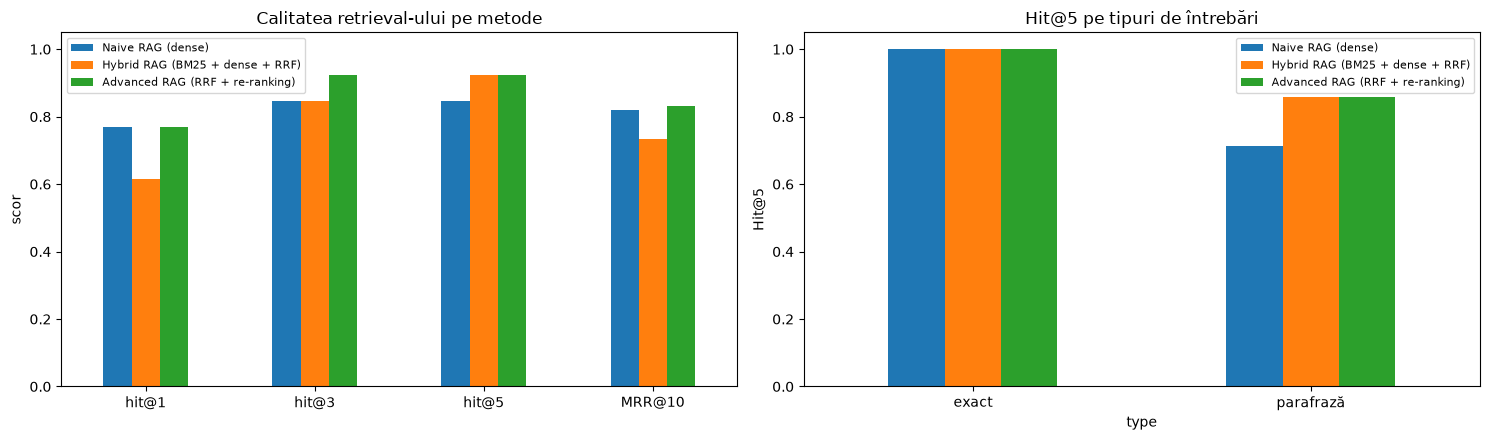

Rangul primului fragment relevant, pe fiecare întrebare (gol = nu apare în top-10):


,method,Naive RAG (dense),Hybrid RAG (BM25 + dense + RRF),Advanced RAG (RRF + re-ranking)
id,type,,,
E1,exact,1.0,1.0,1.0
E3,exact,1.0,1.0,1.0
E4,exact,1.0,1.0,1.0
E5,exact,1.0,1.0,1.0
E6,exact,1.0,1.0,1.0
E7,exact,1.0,1.0,1.0
P1,parafrază,1.0,3.0,1.0
P3,parafrază,1.0,1.0,1.0
P4,parafrază,2.0,2.0,2.0


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
summary[["hit@1", "hit@3", "hit@5", "MRR@10"]].T.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Calitatea retrieval-ului pe metode", ylim=(0, 1.05), ylabel="scor")
axes[0].legend(fontsize=8)

by_type = eval_df.pivot_table(index="type", columns="method", values="hit@5", aggfunc="mean", sort=False)
by_type.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Hit@5 pe tipuri de întrebări", ylim=(0, 1.05), ylabel="Hit@5")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Rangul primului fragment relevant, pe fiecare întrebare (gol = nu apare în top-10):")
display(eval_df.pivot_table(index=["id", "type"], columns="method", values="rank", aggfunc="first", sort=False))

### 12.4 Evaluarea generării
Retrieval-ul bun nu garantează un răspuns bun. Verificăm automat, cu reguli simple și transparente:
- la întrebările **normale**, răspunsul e corect dacă **nu refuză** și **citează cel puțin un articol așteptat**;
- la întrebările **capcană**, răspunsul e corect dacă **refuză** (conține formula de refuz sau o variantă apropiată).

> Sunt 18 întrebări × 3 metode = 54 de apeluri API. Pune `RUN_GENERATION_EVAL = False` în cap. 2 ca să sari peste acest pas.

In [64]:
REFUSAL_MARKERS = ["nu gasesc", "nu se regaseste", "nu contin", "nu am informat",
                   "nu este mentionat", "nu sint informatii", "nu exista informatii"]
CITATION_RE = re.compile(r"\bart(?:icolul|icolului|\.)?\s*(\d+(?:\s*\^\s*\d+)?)", re.I)


def is_refusal(answer: str) -> bool:
    a = norm_title(answer)
    return any(m in a for m in REFUSAL_MARKERS)


def cited_articles(answer: str) -> set:
    return {c.replace(" ", "") for c in CITATION_RE.findall(answer)}


gen_df = None
if RUN_GENERATION_EVAL and LLM_API_KEY:
    rows = []
    for q in tqdm(TEST_SET, desc="Evaluare generare"):
        for m in METHODS:
            out = rag_answer(q["question"], m)
            refused, cited = is_refusal(out["answer"]), cited_articles(out["answer"])
            if q["type"] == "capcană":
                correct = refused
            else:
                correct = (not refused) and bool(cited & set(q["expected_articles"]))
            rows.append({"id": q["id"], "type": q["type"], "method": METHOD_LABELS[m],
                         "correct": int(correct), "refused": int(refused),
                         "cited": ", ".join(sorted(cited)), "answer": out["answer"],
                         "gen_s": out["timings"]["generation_s"]})
            time.sleep(LLM_CALL_DELAY)
    gen_df = pd.DataFrame(rows)

    display(gen_df.pivot_table(index="type", columns="method", values="correct", aggfunc="mean", sort=False)
            .round(2).rename_axis("acuratețe pe tip"))
    display(gen_df.groupby("method", sort=False)[["correct", "gen_s"]].mean().round(2))
    display(gen_df[["id", "method", "correct", "cited"]].assign(
        answer=gen_df["answer"].str.slice(0, 160)))
else:
    print("Evaluarea generării a fost sărită (RUN_GENERATION_EVAL=False sau lipsește cheia API).")

Evaluare generare:   0%|          | 0/18 [00:00<?, ?it/s]

method,Naive RAG (dense),Hybrid RAG (BM25 + dense + RRF),Advanced RAG (RRF + re-ranking)
acuratețe pe tip,,,
exact,0.86,0.86,0.86
parafrază,0.62,0.62,0.75
capcană,1.00,1.00,1.00


,correct,gen_s
method,,
Naive RAG (dense),0.78,1.64
Hybrid RAG (BM25 + dense + RRF),0.78,1.58
Advanced RAG (RRF + re-ranking),0.83,1.58


,id,method,correct,cited,answer
0,E1,Naive RAG (dense),1,"60, 61, 62",Durata maximă a perioadei de probă depinde de tipul contractului:\n\n* **Contract pe durată nedeterminată** – perioa...
1,E1,Hybrid RAG (BM25 + dense + RRF),1,"60, 61",Perioada de probă poate avea o durată diferită în funcție de tipul contractului și de categoria salariatului:\n\n* *...
2,E1,Advanced RAG (RRF + re-ranking),1,"60, 61",Perioada de probă poate avea o durată diferită în funcție de tipul contractului şi de categoria salariatului:\n\n* *...
3,E2,Naive RAG (dense),0,95,Durata normală a timpului de muncă este de **maximum 40 de ore pe săptămână** (art. 95 alin. (2)).
4,E2,Hybrid RAG (BM25 + dense + RRF),0,95,Durata normală a timpului de muncă nu poate depăși **40 de ore pe săptămână** (art. 95 alin. 2).
5,E2,Advanced RAG (RRF + re-ranking),0,95,Durata normală a timpului de muncă nu poate depăși **40 de ore pe săptămână** (art. 95 alin. 2).
6,E3,Naive RAG (dense),1,"104, 105, 95",Munca suplimentară este reglementată prin mai multe prevederi ale Codului muncii:\n\n* **Definiție** – se consideră ...
7,E3,Hybrid RAG (BM25 + dense + RRF),1,"104, 105, 95",Munca suplimentară este reglementată în Codul muncii prin mai multe prevederi:\n\n* **Definiție și condiţii de atrag...
8,E3,Advanced RAG (RRF + re-ranking),1,"104, 95, 96, 98, 99",Munca suplimentară este definită ca „munca prestată în afara duratei normale a timpului de muncă prevăzute la art. 9...
9,E4,Naive RAG (dense),1,"206, 86","Conform art. 206 alin. (1) din Codul muncii, pentru încălcarea disciplinei de muncă angajatorul poate aplica următoa..."


### 12.5 Ablații (experimente suplimentare)
Schimbăm **o singură componentă** pe rând și măsurăm efectul:

- **A. Chunking fix vs. structural:** un chunk fix acoperă de obicei 2–3 articole, deci are mai multe „șanse” să conțină articolul corect. Metrica îl avantajează, deși textul ajuns la LLM e mai zgomotos. Interpretează cu atenție;
- **B. Constanta $k$ din RRF:** un $k$ mic accentuează diferențele dintre primele poziții, un $k$ mare le aplatizează;
- **C. Antetul contextual:** aceleași chunk-uri structurale, cu și fără antetul `Codul muncii | Capitol | Art. N. Titlu`.

> Ablațiile A și C calculează embeddings suplimentare (salvate apoi în cache). Pune `RUN_ABLATIONS = False` ca să sari peste ele.

In [65]:
def build_index(name: str, chunk_list: list) -> RAGIndex:
    emb = embed_passages([c["text"] for c in chunk_list], name)
    collection = f"codul_muncii_{name}"
    create_dense_collection(collection, emb, chunk_list)
    return RAGIndex(name, chunk_list, emb, collection, build_bm25(chunk_list))


def hit_mrr(df: pd.DataFrame) -> pd.DataFrame:
    return summarize(df)[["hit@1", "hit@5", "MRR@10"]]


if RUN_ABLATIONS:
    # A. Chunking fix vs. structural
    fixed_index = build_index("fixed", fixed_chunks)
    fns_a = {}
    for idx in (main_index, fixed_index):
        for m in ("naive", "hybrid"):
            fns_a[f"{idx.name} | {m}"] = (lambda q, m=m, idx=idx: METHODS[m](q, idx, k=EVAL_DEPTH))
    print("A. Strategia de chunking")
    display(hit_mrr(evaluate_retrieval(fns_a, eval_questions)))

    # B. Constanta k din RRF
    fns_b = {f"hybrid k_rrf={kr}": (lambda q, kr=kr: hybrid_search(q, main_index, k=EVAL_DEPTH, k_rrf=kr))
             for kr in (1, 10, 60, 100)}
    print("B. Constanta k din RRF")
    display(hit_mrr(evaluate_retrieval(fns_b, eval_questions)))

    # C. Cu / fără antet contextual
    nohdr_index = build_index("noheader", build_structural_chunks(df_active, MAX_CHUNK_CHARS, with_header=False))
    fns_c = {}
    for idx in (main_index, nohdr_index):
        for m in ("naive", "hybrid"):
            fns_c[f"{idx.name} | {m}"] = (lambda q, m=m, idx=idx: METHODS[m](q, idx, k=EVAL_DEPTH))
    print("C. Antet contextual (structural = cu antet, noheader = fără)")
    display(hit_mrr(evaluate_retrieval(fns_c, eval_questions)))
else:
    print("Ablațiile au fost sărite (RUN_ABLATIONS=False).")

[fixed] embeddings încărcate din cache: emb_fixed_63d439456ecc06a8.npy
Colecția 'codul_muncii_fixed': 507 puncte, dim=768, cosinus
A. Strategia de chunking


Evaluare retrieval:   0%|          | 0/13 [00:00<?, ?it/s]

,hit@1,hit@5,MRR@10
method,,,
structural | naive,0.769,0.846,0.821
structural | hybrid,0.615,0.923,0.733
fixed | naive,0.692,0.923,0.772
fixed | hybrid,0.769,0.923,0.827


B. Constanta k din RRF


Evaluare retrieval:   0%|          | 0/13 [00:00<?, ?it/s]

,hit@1,hit@5,MRR@10
method,,,
hybrid k_rrf=1,0.769,0.846,0.817
hybrid k_rrf=10,0.615,0.923,0.746
hybrid k_rrf=60,0.615,0.923,0.733
hybrid k_rrf=100,0.615,0.923,0.733


[noheader] embeddings încărcate din cache: emb_noheader_afc876a4ae1b436f.npy
Colecția 'codul_muncii_noheader': 589 puncte, dim=768, cosinus
C. Antet contextual (structural = cu antet, noheader = fără)


Evaluare retrieval:   0%|          | 0/13 [00:00<?, ?it/s]

,hit@1,hit@5,MRR@10
method,,,
structural | naive,0.769,0.846,0.821
structural | hybrid,0.615,0.923,0.733
noheader | naive,0.692,0.923,0.762
noheader | hybrid,0.692,0.846,0.757


## 13. Chat interactiv cu Gradio

### 13.1 Conversational RAG: reformularea întrebării
Într-un chat, întrebările depind de istoric:

> **U:** Câte zile de concediu de odihnă am pe an?
> **U:** Și dacă lucrez în condiții grele, **primesc mai multe**?

A doua întrebare, trimisă direct la retrieval, nu conține cuvântul „concediu”. De aceea, înainte de căutare, cerem LLM-ului s-o **reformuleze** ca întrebare de sine stătătoare: *„Primesc concediu de odihnă suplimentar dacă lucrez în condiții grele?”*. Generarea primește apoi și ultimele mesaje din istoric, pentru continuitate.

In [66]:
CONDENSE_PROMPT = """Primești istoricul unei conversații despre Codul muncii al RM și o întrebare nouă.
Reformulează întrebarea nouă astfel încât să poată fi înțeleasă fără istoric (înlocuiește pronumele și referințele cu termenii la care se referă).
Nu răspunde la întrebare. Returnează DOAR întrebarea reformulată, pe un singur rând."""

SOURCES_MARKER = "\n\n---\n**Surse"


def history_to_messages(history, max_messages: int = 6) -> list:
    """Acceptă istoricul Gradio în ambele formate: dicționare {role, content} sau perechi [user, bot]."""
    msgs = []

    def add(role, content):
        if isinstance(content, list):   # conținut structurat (Gradio 6)
            content = " ".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)
        if isinstance(content, str) and content.strip():
            msgs.append({"role": role, "content": content.split(SOURCES_MARKER)[0].strip()})

    for item in history or []:
        if isinstance(item, dict) and item.get("role") in ("user", "assistant"):
            add(item["role"], item.get("content"))
        elif isinstance(item, (list, tuple)) and len(item) == 2:
            add("user", item[0])
            add("assistant", item[1])
    return msgs[-max_messages:]


def condense_question(question: str, history_msgs: list) -> str:
    if not history_msgs:
        return question
    transcript = "\n".join(f"{'Utilizator' if m['role'] == 'user' else 'Asistent'}: {m['content'][:600]}"
                           for m in history_msgs)
    try:
        out = call_llm([{"role": "system", "content": CONDENSE_PROMPT},
                        {"role": "user", "content": f"ISTORIC:\n{transcript}\n\nÎNTREBARE NOUĂ: {question}"}],
                       temperature=0.0)
        line = next((l.strip() for l in out.splitlines() if l.strip()), "")
        return line or question
    except Exception:
        return question


# Test
hist_test = [{"role": "user", "content": "Câte zile de concediu de odihnă am pe an?"},
             {"role": "assistant", "content": "Conform codului, ... (art. 112)"}]
if LLM_API_KEY:
    print("Reformulată:", condense_question("Și dacă lucrez în condiții grele, primesc mai multe?", hist_test))

Reformulată: În cazul în care lucrez în condiții grele, primesc mai multe zile de concediu de odihnă pe an?


### 13.2 Funcția de chat
La fiecare mesaj: istoric → reformulare → retrieval cu metoda aleasă → generare → răspuns + **sursele** (articole și scoruri) + întrebarea reformulată, pentru transparență.

In [67]:
LABEL_TO_METHOD = {v: k for k, v in METHOD_LABELS.items()}


def rag_chat(message: str, history, method_label: str, top_k: float) -> str:
    if not LLM_API_KEY:
        return f"⚠️ Lipsește cheia {LLM_CFG['api_key_env']} în fișierul .env."
    try:
        method = LABEL_TO_METHOD.get(method_label, "rerank")
        hist = history_to_messages(history)
        standalone = condense_question(message, hist)
        results = retrieve(standalone, method, int(top_k))
        answer = call_llm(build_messages(standalone, results, history=hist[-4:]))

        lines = []
        for r in results:
            extra = ""
            if r.get("dense_rank") is not None or r.get("bm25_rank") is not None:
                extra = f" · dense #{r.get('dense_rank') or '-'} · BM25 #{r.get('bm25_rank') or '-'}"
            if r.get("rrf_rank") is not None:
                extra += f" · înainte de rerank #{r['rrf_rank']}"
            lines.append(f"{r['rank']}. Art. {r['art_nr']}. {r['art_titlu']} (scor {r['score']:.4f}{extra})")
        response = f"{answer}{SOURCES_MARKER} ({METHOD_LABELS[method]}):**\n" + "\n".join(lines)
        if standalone.strip() != message.strip():
            response += f"\n\n*Întrebare reformulată pentru căutare:* {standalone}"
        return response
    except Exception as exc:
        return f"⚠️ Eroare: {type(exc).__name__}: {exc}"

### 13.3 Interfața
`gr.ChatInterface` gestionează istoricul automat. Controalele suplimentare permit **comutarea metodei de retrieval în timp real**, pentru a compara metodele pe aceeași întrebare. Interfața apare direct sub celulă (`inline=True`).

In [68]:
default_label = METHOD_LABELS["rerank"]
demo = gr.ChatInterface(
    fn=rag_chat,
    additional_inputs=[
        gr.Radio(choices=list(LABEL_TO_METHOD), value=default_label, label="Metoda de retrieval"),
        gr.Slider(minimum=1, maximum=10, value=TOP_K, step=1, label="Număr de fragmente (top-k)"),
    ],
    title="Asistent RAG – Codul muncii al Republicii Moldova",
    description=("Qdrant (in-memory) + BM25 + RRF + cross-encoder · LLM: "
                 f"{LLM_MODEL} prin {LLM_PROVIDER}. Proiect educațional, nu oferă consultanță juridică."),
    examples=[
        ["Câte zile de concediu de odihnă am pe an?", default_label, TOP_K],
        ["Vreau să plec de la job. Cu cât timp înainte trebuie să-l anunț pe șef?", default_label, TOP_K],
        ["Mă poate da afară angajatorul cât timp sunt în concediu medical?", default_label, TOP_K],
    ],
)
demo.launch(inline=True, share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Pentru a opri serverul Gradio (de exemplu, înainte de o nouă rulare):

In [ ]:
# demo.close()

## 14. Concluzii

### 14.1 Rezumatul rezultatelor

In [69]:
print("Retrieval (structural, adâncime 10):")
display(summary)
if gen_df is not None:
    print("Generare (acuratețe medie):")
    display(gen_df.groupby("method", sort=False)["correct"].mean().round(2))
print(f"\nSursa: {meta['source_url']} | obținută: {meta['retrieved_at']} | sha256: {meta['sha256'][:12]}...")

Retrieval (structural, adâncime 10):


,hit@1,hit@3,hit@5,MRR@10,latency_s
method,,,,,
Naive RAG (dense),0.769,0.846,0.846,0.821,0.031
Hybrid RAG (BM25 + dense + RRF),0.615,0.846,0.923,0.733,0.030
Advanced RAG (RRF + re-ranking),0.769,0.923,0.923,0.833,10.211


Generare (acuratețe medie):


method
Naive RAG (dense)                  0.78
Hybrid RAG (BM25 + dense + RRF)    0.78
Advanced RAG (RRF + re-ranking)    0.83
Name: correct, dtype: float64


Sursa: https://www.legis.md/cautare/getResults?doc_id=8238&lang=ro | obținută: 2026-10-26T18:18:28 | sha256: 433744ddee26...


**Interpretare**:


Pe setul de 13 întrebări cu răspuns, toate cele trei metode găsesc articolul corect în top-5 în peste 84% din cazuri. Hybrid RAG crește acoperirea (Hit@5: 0.846 → 0.923) datorită componentei BM25, dar scade precizia pe primul loc (Hit@1: 0.769 → 0.615), pentru că RRF poate promova fragmente cu potrivire lexicală, dar irelevante. Re-ranking-ul cu cross-encoder corectează acest efect (Hit@1 0.769, MRR@10 0.833, cel mai bun rezultat), cu prețul unei latențe de ~10 s pe interogare pe CPU, față de 0.03 s. La generare, Hybrid și Advanced RAG au aceeași acuratețe (0.83 față de 0.78 la Naive): cu 5 fragmente în context, LLM-ul răspunde corect dacă articolul relevant e prezent, indiferent de poziție. Diferențele reprezintă 1–2 întrebări, deci sunt orientative; pentru concluzii ferme ar fi necesar un set de test mai mare.

### 14.2 Limitări
- **Versiune fixă a legii:** textul reflectă data descărcării (vezi `meta.json`), iar modificările ulterioare lipsesc;
- **setul de test e mic** (18 întrebări), iar articolele „corecte” sunt definite prin cuvinte-cheie din titlu, deci pot fi prea largi sau prea înguste;
- **BM25 nu înțelege sinonimele sau flexiunile** (fără lematizare pentru română);
- **evaluarea generării e euristică** (refuz și citare corectă), nu verifică dacă tot conținutul răspunsului e corect;
- **re-rankerul e lent pe CPU**, de aceea limităm numărul de candidați.

### 14.3 Direcții de dezvoltare
- **transformarea interogării:** HyDE (generăm un răspuns ipotetic și căutăm după el) sau Multi-Query;
- **evaluare cu LLM-as-a-judge** sau cu framework-uri precum Ragas (faithfulness, answer relevancy, context precision);
- **lematizare pentru română** (de exemplu, spaCy `ro_core_news_sm`) pentru BM25;
- **fine-tuning al embeddings-urilor** pe perechi întrebare–articol din domeniul juridic;
- **extinderea corpusului** cu Codul fiscal sau Codul civil, cu filtrare după metadate (cod/capitol) în Qdrant.